# The training loop, made to tell the truth

**ERA V5 · Session 10.** Session 9 ended with one number, the loss. This notebook follows that number backwards
through a real **124M-parameter GPT-2** training on an **NVIDIA RTX PRO 6000 Blackwell**, and checks every claim
instead of trusting it.

| # | The assignment asks | Where |
|---|---|---|
| 1 | Print every tensor shape in the step, one line per dimension | §1 |
| 2 | Verify one gradient by hand: nudge a weight, compare with `backward()` | §2 |
| 3 | Break gradient accumulation on purpose, plot both curves | §3 |
| 4 | Log the grad norm every step, find a step where it moved before the loss | §4 |
| 5 | Compute my own MFU, honestly, and explain the distance to 40% | §5 |
| 6 | Write 0.1 in fp32, bf16 and fp8 E4M3 by hand, pick a training format | §6 |

**Setup.** GPT-2 small: 12 layers, 12 heads, C = 768, context 1,024, GPT-2 tokenizer (V padded to 50,304), tied
embeddings, bf16 autocast. Data is **TinyStories**: short stories of very different lengths, which §3 needs.

**Words used below:**

| word | meaning in one line |
|---|---|
| **B, T, C, V** | batch size (sequences per step), context length (tokens per sequence), channel width, vocabulary size |
| **step** | one forward pass, one loss, one `backward()`, one optimiser update |
| **gradient** | for every weight, how much the loss would change if that weight moved a little; `backward()` computes all of them |
| **micro-batch** | a slice of a batch, run separately when the whole batch does not fit in memory |
| **gradient accumulation** | running several micro-batches and adding their gradients before one update, to act like one big batch |
| **grad norm** | the length of the whole gradient as one vector: a single number for how hard this step wants to move the weights |
| **clipping** | if the grad norm is above a threshold (1.0 here), shrink the gradient to that length before the update |
| **FLOP** | one floating-point multiply or add; a matmul of (m×k)·(k×n) costs 2·m·k·n |
| **MFU** | model FLOPs utilisation: useful model arithmetic per second, divided by what the GPU could do at peak |
| **fp32 / bf16 / fp8** | number formats with 32, 16 and 8 bits; fewer bits are faster and smaller but hold fewer digits |
| **autocast** | a PyTorch mode that runs matmuls in bf16 while the weights themselves stay stored in fp32 |
| **tied embeddings** | the input embedding table `wte` is reused as the output head: one matrix both reads tokens in and scores them out |

This is a [marimo](https://marimo.io) notebook, so it is reactive: the measured numbers quoted in the prose are
computed from the cells above it, not typed in. Three cells are interactive: the nudge size in §2, the zoom step in
§4, and a float encoder in §6.

In [ ]:
import copy
import math
import os
import shutil
import pickle
import struct
import subprocess
import threading
import time
import urllib.request
from fractions import Fraction
from pathlib import Path

import marimo as mo
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tiktoken
import torch
import torch.nn as nn
import torch.nn.functional as F

FIGURES = 'https://raw.githubusercontent.com/revantg/training-loop-truth/main/figures/'
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)

INK, ROSE, TEAL, AMBER, SLATE, SKY = '#4F46E5', '#E11D48', '#0D9488', '#F59E0B', '#64748B', '#0EA5E9'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 110, 'font.size': 10.5,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.25,
    'axes.titleweight': 'bold', 'axes.titlesize': 12, 'axes.titlelocation': 'left', 'legend.frameon': False,
})


def figure(name):
    """One of the hand-drawn SVG diagrams that live in the repo."""
    return mo.Html(urllib.request.urlopen(FIGURES + name).read().decode())


def save(fig, name):
    """Keep a PNG of a plot for the README, and return the figure so the cell still shows it."""
    fig.savefig(RESULTS / name, bbox_inches='tight')
    return fig

In [ ]:
dev = 'cuda' if torch.cuda.is_available() else 'cpu'
AMP = torch.bfloat16                           # bf16 autocast: same exponent range as fp32, so no loss scaler
torch.backends.cuda.matmul.allow_tf32 = False  # "float32" below means real float32; §2 and §3 depend on it
torch.backends.cudnn.allow_tf32 = False

_props = torch.cuda.get_device_properties(0)
_smi = subprocess.run(['nvidia-smi', '--query-gpu=clocks.max.sm,power.limit', '--format=csv,noheader,nounits'],
                      capture_output=True, text=True).stdout.split(',')
GPU = {
    'name': _props.name,
    'memory_gb': _props.total_memory / 1e9,
    'sms': _props.multi_processor_count,
    'max_sm_mhz': float(_smi[0]),
    'power_limit_w': float(_smi[1]),
}
mo.md(f"**{GPU['name']}**: {GPU['sms']} SMs, {GPU['memory_gb']:.0f} GB, SM clock up to {GPU['max_sm_mhz']:.0f} MHz, "
      f"{GPU['power_limit_w']:.0f} W power limit · PyTorch {torch.__version__}, autocast `{AMP}`")

**NVIDIA RTX PRO 6000 Blackwell Server Edition**: 188 SMs, 102 GB, SM clock up to 2430 MHz, 600 W power limit · PyTorch 2.11.0+cu130, autocast `torch.bfloat16`

In [ ]:
TS = 'https://huggingface.co/datasets/roneneldan/TinyStories/resolve/main/'
TRAIN_BYTES = 200 * 2**20      # the first 200 MB of the 2.2 GB training file: ~51M tokens, more than this notebook uses
os.makedirs('data', exist_ok=True)
if not os.path.exists('data/train.txt'):
    _request = urllib.request.Request(TS + 'TinyStoriesV2-GPT4-train.txt', headers={'Range': f'bytes=0-{TRAIN_BYTES - 1}'})
    Path('data/train.txt').write_bytes(urllib.request.urlopen(_request).read())
if not os.path.exists('data/valid.txt'):
    urllib.request.urlretrieve(TS + 'TinyStoriesV2-GPT4-valid.txt', 'data/valid.txt')

enc = tiktoken.get_encoding('gpt2')
EOS = enc.eot_token


def load_stories(path, cut_mid_story):
    """One list of token ids per story, each ending in EOS."""
    text = Path(path).read_text(encoding='utf-8', errors='ignore')
    stories = [s.strip() for s in text.split('<|endoftext|>')]
    if cut_mid_story:
        stories = stories[:-1]        # the byte range above ends somewhere inside a story
    return [ids + [EOS] for ids in enc.encode_ordinary_batch([s for s in stories if s], num_threads=16)]


train_docs = load_stories('data/train.txt', cut_mid_story=True)
val_docs = load_stories('data/valid.txt', cut_mid_story=False)
# The language-model runs read from one long packed stream; §3 needs the individual stories instead.
train_data = torch.tensor([t for d in train_docs for t in d], dtype=torch.long, device=dev)
val_data = torch.tensor([t for d in val_docs for t in d], dtype=torch.long, device=dev)

_lens = np.array([len(d) for d in train_docs])
mo.md(f"""
| training stories | training tokens | held-out tokens | median story length |
|---|---|---|---|
| **{len(train_docs):,}** | **{len(train_data) / 1e6:.1f}M** | **{len(val_data) / 1e6:.2f}M** ({len(val_docs):,} stories) | **{np.median(_lens):.0f}** tokens (10th pct {np.percentile(_lens, 10):.0f}, 90th pct {np.percentile(_lens, 90):.0f}) |
""")

| training stories | training tokens | held-out tokens | median story length |
|---|---|---|---|
| **256,006** | **51.0M** | **5.47M** (27,630 stories) | **177** tokens (10th pct 137, 90th pct 270) |

In [ ]:
class Cfg:
    vocab = 50304    # GPT-2's 50,257 rounded up to a multiple of 64, which tensor cores prefer
    block = 1024     # context length T
    n_layer = 12
    n_head = 12
    n_embd = 768     # channel width C


def shape_row(name, tensor, meaning):
    return (name, tuple(tensor.shape), str(tensor.dtype).removeprefix('torch.'), meaning)


def note(shapes, name, tensor, meaning):
    """Record a tensor's shape when a list is passed in; otherwise just hand the tensor back."""
    if shapes is not None:
        shapes.append(shape_row(name, tensor, meaning))
    return tensor


class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        C = cfg.n_embd
        self.n_head = cfg.n_head
        self.ln1 = nn.LayerNorm(C)
        self.ln2 = nn.LayerNorm(C)
        self.c_attn = nn.Linear(C, 3 * C)
        self.attn_proj = nn.Linear(C, C)
        self.fc = nn.Linear(C, 4 * C)
        self.mlp_proj = nn.Linear(4 * C, C)

    def forward(self, x, shapes=None):
        B, T, C = x.shape
        head_dim = C // self.n_head

        qkv = note(shapes, 'qkv = c_attn(ln1(x))', self.c_attn(self.ln1(x)), 'B, T, 3C: q, k and v for every position, side by side')
        q, k, v = (t.view(B, T, self.n_head, head_dim).transpose(1, 2) for t in qkv.split(C, dim=2))
        note(shapes, 'q (k, v identical)', q, 'B, heads, T, head_dim: each head works on its own 64-wide slice of C')
        if shapes is not None:
            # SDPA never materialises the T×T score matrix; a 'meta' tensor records its shape without allocating it.
            scores = torch.empty(B, self.n_head, T, T, device='meta', dtype=q.dtype)
            shapes.append(shape_row('scores q·kᵀ/√d (virtual)', scores, 'B, heads, T_query, T_key: fused inside SDPA, never stored'))
        y = note(shapes, 'softmax(scores)·v', F.scaled_dot_product_attention(q, k, v, is_causal=True),
                 'B, heads, T, head_dim: a weighted mix of earlier v')
        y = note(shapes, 'heads merged', y.transpose(1, 2).reshape(B, T, C), 'B, T, C: heads concatenated back into the channel axis')
        x = note(shapes, 'x + attn_proj(y)', x + self.attn_proj(y), 'B, T, C: residual stream after attention')

        h = note(shapes, 'fc(ln2(x))', self.fc(self.ln2(x)), 'B, T, 4C: the MLP widens every position 4x')
        return note(shapes, 'x + mlp_proj(gelu(h))', x + self.mlp_proj(F.gelu(h)), 'B, T, C: residual stream leaving the block')


class GPT(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.wte = nn.Embedding(cfg.vocab, cfg.n_embd)
        self.wpe = nn.Embedding(cfg.block, cfg.n_embd)
        self.blocks = nn.ModuleList(Block(cfg) for _ in range(cfg.n_layer))
        self.ln_f = nn.LayerNorm(cfg.n_embd)
        self.head = nn.Linear(cfg.n_embd, cfg.vocab, bias=False)
        self.head.weight = self.wte.weight    # tied: one matrix both reads tokens in and scores them out

        # GPT-2 init: N(0, 0.02), with the projections that write into the residual stream scaled down by
        # sqrt(2 · n_layer) so the stream's variance does not grow with depth.
        for name, p in self.named_parameters():
            if p.dim() == 2:
                std = 0.02 / math.sqrt(2 * cfg.n_layer) if name.endswith('proj.weight') else 0.02
                nn.init.normal_(p, 0.0, std)
            elif name.endswith('bias'):
                nn.init.zeros_(p)

    def forward(self, idx, shapes=None):
        B, T = note(shapes, 'idx', idx, 'B, T: token ids, B sequences of T positions').shape
        tok = note(shapes, 'wte(idx)', self.wte(idx), 'B, T, C: one C-wide vector per token')
        pos = note(shapes, 'wpe(arange(T))', self.wpe(torch.arange(T, device=idx.device)), 'T, C: one vector per position, broadcast over B')
        x = note(shapes, 'x = tok + pos', tok + pos, 'B, T, C: the residual stream')
        for i, block in enumerate(self.blocks):
            x = block(x, shapes if i == 0 else None)     # the other eleven blocks have identical shapes
        note(shapes, 'after all 12 blocks', x, 'B, T, C: blocks 1-11 repeat block 0 exactly')
        x = note(shapes, 'ln_f(x)', self.ln_f(x), 'B, T, C: normalised before the head')
        return note(shapes, 'logits = head(x)', self.head(x), 'B, T, V: a score for every vocabulary entry at every position')


def n_params(model, exclude_pos=False):
    n = sum(p.numel() for p in model.parameters())
    return n - model.wpe.weight.numel() if exclude_pos else n


V = Cfg.vocab
with torch.device('meta'):                 # count parameters without allocating them
    N_TOTAL = n_params(GPT(Cfg()))
mo.md(f'GPT-2 small, **{N_TOTAL:,} parameters**')

GPT-2 small, **124,475,904 parameters**

In [ ]:
def get_batch(split, B, T, gen=None):
    """B random windows of T tokens from the packed stream; the target is the same window shifted by one."""
    data = train_data if split == 'train' else val_data
    starts = torch.randint(len(data) - T - 1, (B,), generator=gen).to(dev)
    offsets = torch.arange(T, device=dev)
    return data[starts[:, None] + offsets], data[starts[:, None] + offsets + 1]


def autocast():
    return torch.autocast(dev, dtype=AMP)


def make_opt(model, lr):
    # Weight decay on matrices only; biases and layernorm gains are left alone.
    decay = [p for p in model.parameters() if p.dim() >= 2]
    no_decay = [p for p in model.parameters() if p.dim() < 2]
    groups = [{'params': decay, 'weight_decay': 0.1}, {'params': no_decay, 'weight_decay': 0.0}]
    return torch.optim.AdamW(groups, lr=lr, betas=(0.9, 0.95), fused=(dev == 'cuda'))


def lr_at(step, peak, warmup, total, floor=0.1):
    """Linear warmup, then cosine decay down to floor × peak."""
    if step < warmup:
        return peak * (step + 1) / warmup
    progress = (step - warmup) / max(1, total - warmup)
    return peak * (floor + (1 - floor) * 0.5 * (1 + math.cos(math.pi * progress)))


def sync():
    if dev == 'cuda':
        torch.cuda.synchronize()


def smooth(a, k=25):
    return np.convolve(a, np.ones(k) / k, 'valid')


def cached(name, compute):
    """Run an expensive experiment once and keep the result in results/<name>.pkl; delete the file to rerun it."""
    path = RESULTS / f'{name}.pkl'
    if path.exists():
        return pickle.loads(path.read_bytes())
    value = compute()
    path.write_bytes(pickle.dumps(value))
    return value

In [ ]:
mo.vstack([
    mo.md(
        r"""
        ## 1 · Every tensor shape in one step

        **What and why.** We run one real training step and list the shape of every tensor in it. Later sections lean on
        these shapes: the memory cost of the logits and the FLOP count in §5 both come straight from them.

        One step is five lines: forward, loss, backward, update, wipe (clear the gradients). The figure is the map. The
        table below it comes from **the exact step used for training**:

        * bf16 autocast for the forward pass;
        * logits upcast to fp32 for the loss;
        * gradient clipping, then a fused AdamW update.

        **B = 16 sequences · T = 1,024 positions · C = 768 channels · V = 50,304 vocabulary entries · 12 heads × 64 dims.**
        """
    ),
    figure('01-one-step.svg'),
])

1 · Every tensor shape in one step 
 What and why. We run one real training step and list the shape of every tensor in it. Later sections lean on
these shapes: the memory cost of the logits and the FLOP count in §5 both come straight from them. 
 One step is five lines: forward, loss, backward, update, wipe (clear the gradients). The figure is the map. The
table below it comes from the exact step used for training : 
 
 bf16 autocast for the forward pass; 
 logits upcast to fp32 for the loss; 
 gradient clipping, then a fused AdamW update. 
 
 B = 16 sequences · T = 1,024 positions · C = 768 channels · V = 50,304 vocabulary entries · 12 heads × 64 dims. 
 Anatomy of one training step 
 
 
 
 
 
 
 One step, five lines 
 forward → loss → backward → clip → update → wipe. Shapes are for B=16, T=1024, C=768, V=50,304. 

 <!-- stage cards -->
 
 
 
 1 · forward 
 x [B, T] 
 h [B, T, C] 
 logits [B, T, V] 
 graph recorded for 
 every op (autograd) 
 
 
 
 2 · loss 
 [B·T, V] vs [B·T] 
 → loss [ ] 
 16,384 predictions 
 collapse to 
 one number 
 
 
 
 3 · backward 
 p.grad.shape 
 == p.shape 
 chain rule, one link 
 at a time; grads 
 add, never replace 
 
 
 
 4 · clip 
 ‖g‖ = √Σ g² 
 g ×= min(1, 1/‖g‖) 
 length capped, 
 direction kept; 
 log ‖g‖ every step 
 
 
 
 5 · step + wipe 
 w −= lr · update 
 grad = None 
 AdamW keeps m, v 
 per weight; wipe or 
 batch 2 sits on batch 1 
 
 
 
 
 
 
 <!-- backward sweep -->
 
 gradients flow back through the recorded graph, output head first, embeddings last 

 <!-- memory strip -->
 What the step must hold, per weight (mixed precision + AdamW) 
 
 weight 2 B 
 grad 2 B 
 fp32 master copy 4 B 
 AdamW m and v, fp32: 8 B 
 = 16 B

In [ ]:
def _record_one_step():
    torch.manual_seed(0)
    model = GPT(Cfg()).to(dev)
    opt = make_opt(model, 6e-4)
    x, y = get_batch('train', 16, Cfg.block, torch.Generator().manual_seed(0))

    shapes = []
    with autocast():
        logits = model(x, shapes)                               # 1. forward: matmuls run in bf16 under autocast
    logits.retain_grad()                                        #    keep d(loss)/d(logits) so it can be inspected
    logits32 = logits.float()                                   #    the loss is computed on an fp32 copy
    loss = F.cross_entropy(logits32.view(-1, V), y.view(-1))    # 2. loss
    loss.backward()                                             # 3. backward
    grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # 4. clip, and the norm to log
    opt.step()                                                  # 5. update ...

    wte = model.wte.weight
    block0 = model.blocks[0]
    gb = logits32.numel() * 4 / 1e9
    rows = shapes + [
        shape_row('logits.float()', logits32, f'B, T, V: the same scores upcast for a stable loss; {logits32.numel():,} × 4 B = {gb:.1f} GB'),
        shape_row('y (targets)', y, 'B, T: x shifted left by one, the token each position must predict'),
        shape_row('logits.view(-1, V)', logits32.view(-1, V), f'B·T, V: every position becomes one {V:,}-way classification'),
        shape_row('loss', loss, f'(): one scalar, the mean over all {y.numel():,} predictions'),
        shape_row('logits.grad', logits.grad, 'B, T, V: (softmax − one_hot)/(B·T); bf16 because the logits were bf16'),
        shape_row('wte.weight.grad', wte.grad, "V, C: always the weight's own shape; tied, so it sums the head and embedding paths"),
        shape_row('wpe.weight.grad', model.wpe.weight.grad, 'T, C: one gradient row per position'),
        shape_row('blocks[0].c_attn.weight.grad', block0.c_attn.weight.grad, '3C, C: nn.Linear stores (out_features, in_features)'),
        shape_row('blocks[0].c_attn.bias.grad', block0.c_attn.bias.grad, '3C: one bias per q, k, v channel'),
        shape_row('blocks[0].fc.weight.grad', block0.fc.weight.grad, '4C, C: the MLP up-projection'),
        shape_row('blocks[0].mlp_proj.weight.grad', block0.mlp_proj.weight.grad, 'C, 4C: the MLP down-projection'),
        shape_row('ln_f.weight.grad', model.ln_f.weight.grad, 'C: one gain per channel'),
        shape_row('grad norm', grad_norm, f'(): one number summarising all {N_TOTAL / 1e6:.0f}M gradients, logged every step'),
        shape_row('AdamW step (wte)', opt.state[wte]['step'], '(): how many updates this weight has had'),
        shape_row('AdamW exp_avg (wte)', opt.state[wte]['exp_avg'], 'V, C: running mean of the gradient, per weight'),
        shape_row('AdamW exp_avg_sq (wte)', opt.state[wte]['exp_avg_sq'], 'V, C: running mean of the squared gradient, per weight'),
    ]

    named = list(model.named_parameters())
    missing = [name for name, p in named if p.grad is None or p.grad.shape != p.shape]
    assert not missing, f'parameters with a missing or mis-shaped grad: {missing}'

    # A right shape can still hold wrong numbers: logits.grad must equal (softmax − one_hot) / (B·T).
    grad = logits.grad.float()
    expected = (logits.detach().float().softmax(-1) - F.one_hot(y, V).float()) / y.numel()
    checks = {
        'n_param_tensors': len(named),
        'row_sum': grad.sum(-1).abs().max().item(),
        'mismatch': ((grad - expected).abs().max() / expected.abs().max()).item(),
        'wte': wte.numel(),
        'wpe': model.wpe.weight.numel(),
        'block': sum(p.numel() for p in block0.parameters()),
        'total': n_params(model),
    }
    opt.zero_grad(set_to_none=True)                             # ... and wipe
    return rows, checks


shape_rows, step_checks = _record_one_step()
mo.plain(pd.DataFrame(shape_rows, columns=['tensor', 'shape', 'dtype', 'what each dimension means']))

,tensor,shape,dtype,what each dimension means
0,idx,"(16, 1024)",int64,"B, T: token ids, B sequences of T positions"
1,wte(idx),"(16, 1024, 768)",float32,"B, T, C: one C-wide vector per token"
2,wpe(arange(T)),"(1024, 768)",float32,"T, C: one vector per position, broadcast over B"
3,x = tok + pos,"(16, 1024, 768)",float32,"B, T, C: the residual stream"
4,qkv = c_attn(ln1(x)),"(16, 1024, 2304)",bfloat16,"B, T, 3C: q, k and v for every position, side by side"
...,...,...,...,...
26,ln_f.weight.grad,"(768,)",float32,C: one gain per channel
27,grad norm,(),float32,"(): one number summarising all 124M gradients, logged every step"
28,AdamW step (wte),(),float32,(): how many updates this weight has had
29,AdamW exp_avg (wte),"(50304, 768)",float32,"V, C: running mean of the gradient, per weight"


In [ ]:
mo.md(f"""
Two checks on the shapes, because a right shape can still hold wrong numbers:

* **Every parameter has a gradient of exactly its own shape.** All {step_checks['n_param_tensors']} parameter tensors pass.
  None is left with `grad=None` (asserted in the cell above, before `zero_grad` wiped them).
* **`logits.grad` matches the formula `(softmax − one_hot)/(B·T)`.** Every row sums to zero (largest |row sum|
  {step_checks['row_sum']:.1e}). The largest difference from the formula is {step_checks['mismatch']:.1e} of its largest
  entry. That is bf16 storage (8 significant bits, about 4×10⁻³ relative), not a bug; §2 does the exact float64 check.

**Where the parameters are.** The tied embedding holds **{step_checks['wte']:,}**, positions {step_checks['wpe']:,}, and each
of the 12 blocks {step_checks['block']:,}, for **{step_checks['total']:,}** in total. The head re-uses `wte`, so it adds
nothing; untied, it would add another {step_checks['wte'] / 1e6:.1f}M.
""")

Two checks on the shapes, because a right shape can still hold wrong numbers:

* **Every parameter has a gradient of exactly its own shape.** All 148 parameter tensors pass.
  None is left with `grad=None` (asserted in the cell above, before `zero_grad` wiped them).
* **`logits.grad` matches the formula `(softmax − one_hot)/(B·T)`.** Every row sums to zero (largest |row sum|
  1.0e-08). The largest difference from the formula is 1.6e-04 of its largest
  entry. That is bf16 storage (8 significant bits, about 4×10⁻³ relative), not a bug; §2 does the exact float64 check.

**Where the parameters are.** The tied embedding holds **38,633,472**, positions 786,432, and each
of the 12 blocks 7,087,872, for **124,475,904** in total. The head re-uses `wte`, so it adds
nothing; untied, it would add another 38.6M.

In [ ]:
mo.vstack([
    mo.md(
        r"""
        ## 2 · One gradient, checked by hand

        **What and why.** We check that `backward()` returns the right gradient by measuring it a second, independent way.
        Every update in training is built from these gradients, so everything later depends on them being right.

        * **`backward()`** multiplies local slopes from the loss back to each weight (the chain rule).
        * **The nudge** needs no calculus. Move one weight up by ε, then down by ε, and measure the loss both times. The
          slope is (L₊ − L₋)/2ε. This is a **central difference**, and its error shrinks like ε².

        In **float64** (64-bit floats, roundoff around 10⁻¹⁶) the two should agree to many digits. First the lecture's toy
        chain, then the real model.
        """
    ),
    figure('02-nudge.svg'),
])

2 · One gradient, checked by hand 
 What and why. We check that backward() returns the right gradient by measuring it a second, independent way.
Every update in training is built from these gradients, so everything later depends on them being right. 
 
 backward() multiplies local slopes from the loss back to each weight (the chain rule). 
 The nudge needs no calculus. Move one weight up by ε, then down by ε, and measure the loss both times. The
 slope is (L₊ − L₋)/2ε. This is a central difference , and its error shrinks like ε². 
 
 In float64 (64-bit floats, roundoff around 10⁻¹⁶) the two should agree to many digits. First the lecture's toy
chain, then the real model. 
 Two ways to get one gradient 
 
 
 
 
 
 Two roads to the same number 
 Autograd multiplies local slopes backwards. The nudge just asks the loss. If they disagree, the graph is lying. 

 <!-- left: chain -->
 
 
 backward(): chain rule, loss → weight 
 
 w 
 h 
 logits 
 loss 
 
 
 
 
 
 ∂L/∂z × ∂z/∂h × ∂h/∂w 
 
 One pass gives all 124M gradients at once. 
 Cost: about 2× a forward pass, for every weight. 
 

 <!-- right: nudge -->
 
 
 the nudge: central difference 
 
 
 
 
 w−ε 
 w+ε 
 L(w+ε) − L(w−ε) 
 
 2ε 
 error ∝ ε², not ε 
 run in float64, no dropout, 
 same batch both times

In [ ]:
def _toy_chain():
    # The lecture's chain: x = 2, w1 = 3, w2 = 4, target 20, loss = (w2 · w1 · x − target)².
    w1 = torch.tensor(3.0, dtype=torch.float64, requires_grad=True)
    w2 = torch.tensor(4.0, dtype=torch.float64)

    def loss(w):
        return (w2 * (w * 2.0) - 20.0) ** 2

    loss(w1).backward()
    eps = 1e-6
    nudge = (loss(w1 + eps) - loss(w1 - eps)) / (2 * eps)
    return w1.grad.item(), nudge.item()


_analytic, _numeric = _toy_chain()
mo.md(f'**Lecture chain:** `backward()` says {_analytic:.8f}, the nudge says {_numeric:.8f}.')

**Lecture chain:** `backward()` says 64.00000000, the nudge says 64.00000001.

In [ ]:
torch.manual_seed(0)
m64 = GPT(Cfg()).to(dev).double()          # float64 copy: roundoff ~1e-16, and no autocast
xb, yb = get_batch('train', 4, 64, torch.Generator().manual_seed(1))


def loss64():
    return F.cross_entropy(m64(xb).view(-1, V), yb.view(-1))


def _check_by_hand(h=1e-5):
    m64.zero_grad()
    loss64().backward()
    tok = int(xb[0, 5])                     # a token that really appears in the batch
    targets = [
        ('blocks[0].fc.weight', m64.blocks[0].fc.weight, None),
        ('blocks[11].attn_proj.weight', m64.blocks[11].attn_proj.weight, None),
        ('ln_f.weight', m64.ln_f.weight, None),
        ('wpe.weight (position 3)', m64.wpe.weight, (3, 7)),
        (f'wte.weight (token {enc.decode([tok])!r}, tied)', m64.wte.weight, (tok, 11)),
    ]
    rows = []
    with torch.no_grad():
        for name, param, idx in targets:
            if idx is None:                 # default: the entry with the largest gradient, the one that matters most
                idx = np.unravel_index(int(param.grad.abs().argmax()), param.shape)
            analytic = param.grad[idx].item()
            w0 = param[idx].item()
            param[idx] = w0 + h
            loss_plus = loss64().item()
            param[idx] = w0 - h
            loss_minus = loss64().item()
            param[idx] = w0                 # put the weight back exactly
            numeric = (loss_plus - loss_minus) / (2 * h)
            index = tuple(int(i) for i in np.atleast_1d(idx))
            rows.append((name, index, analytic, numeric, abs(numeric - analytic) / abs(analytic)))
    return rows


nudge_rows = _check_by_hand()
fc_idx = tuple(nudge_rows[0][1])           # the largest-gradient weight of blocks[0].fc, reused below
fc_analytic = nudge_rows[0][2]
pd.DataFrame(nudge_rows, columns=['weight', 'index', 'backward()', 'nudge (L₊−L₋)/2ε', 'relative error']).style.format(
    {'backward()': '{:.10e}', 'nudge (L₊−L₋)/2ε': '{:.10e}', 'relative error': '{:.1e}'})

,weight,index,backward(),nudge (L₊−L₋)/2ε,relative error
0,blocks[0].fc.weight,"(226, 172)",-1.5847614695e-02,-1.5847614776e-02,5.1e-09
1,blocks[11].attn_proj.weight,"(117, 126)",3.3195668480e-02,3.3195668347e-02,4.0e-09
2,ln_f.weight,"(160,)",1.3021630272e-02,1.3021630263e-02,7.0e-10
3,wpe.weight (position 3),"(3, 7)",2.8132383284e-02,2.8132383179e-02,3.7e-09
4,"wte.weight (token ' ball', tied)","(2613, 11)",1.0891659402e-02,1.0891659397e-02,4.7e-10


In [ ]:
_errs = [r[-1] for r in nudge_rows]
_digits = [-math.log10(e) for e in _errs]
mo.md(
    f"""
    **`backward()` is right: the two agree to {min(_digits):.0f}–{max(_digits):.0f} significant digits** (relative error
    {min(_errs):.0e} to {max(_errs):.0e}, central difference with ε = 10⁻⁵ in float64).

    The five weights are the largest-gradient entry of three layers, plus one hand-picked position-embedding entry and
    one hand-picked tied-token entry.

    The tied `wte` entry is the interesting one. Its gradient is the *sum* of two paths: the embedding lookup at the bottom
    and the output head at the top. The nudge only asks the loss, so it sees both paths at once. Agreement there also
    confirms that autograd adds the two contributions correctly.

    **Where it stops agreeing.** Now repeat the nudge in the precisions we actually train in. Two errors pull in opposite
    directions:

    * **truncation** (∝ ε²): the central difference is an approximation, and it hurts at large ε;
    * **roundoff** (∝ machine-ε·|L|/ε): each loss is stored with limited digits, and it hurts at small ε. *Machine-ε* is
      the relative gap between 1 and the next number the format can store.

    A loss of ~11 stored in fp32 is only known to about ±10⁻⁶. So a nudge of 10⁻⁵ moves it by less than its own rounding
    noise.
    """
)

**`backward()` is right: the two agree to 8–9 significant digits** (relative error
5e-10 to 5e-09, central difference with ε = 10⁻⁵ in float64).

The five weights are the largest-gradient entry of three layers, plus one hand-picked position-embedding entry and
one hand-picked tied-token entry.

The tied `wte` entry is the interesting one. Its gradient is the *sum* of two paths: the embedding lookup at the bottom
and the output head at the top. The nudge only asks the loss, so it sees both paths at once. Agreement there also
confirms that autograd adds the two contributions correctly.

**Where it stops agreeing.** Now repeat the nudge in the precisions we actually train in. Two errors pull in opposite
directions:

* **truncation** (∝ ε²): the central difference is an approximation, and it hurts at large ε;
* **roundoff** (∝ machine-ε·|L|/ε): each loss is stored with limited digits, and it hurts at small ε. *Machine-ε* is
  the relative gap between 1 and the next number the format can store.

A loss of ~11 stored in fp32 is only known to about ±10⁻⁶. So a nudge of 10⁻⁵ moves it by less than its own rounding
noise.

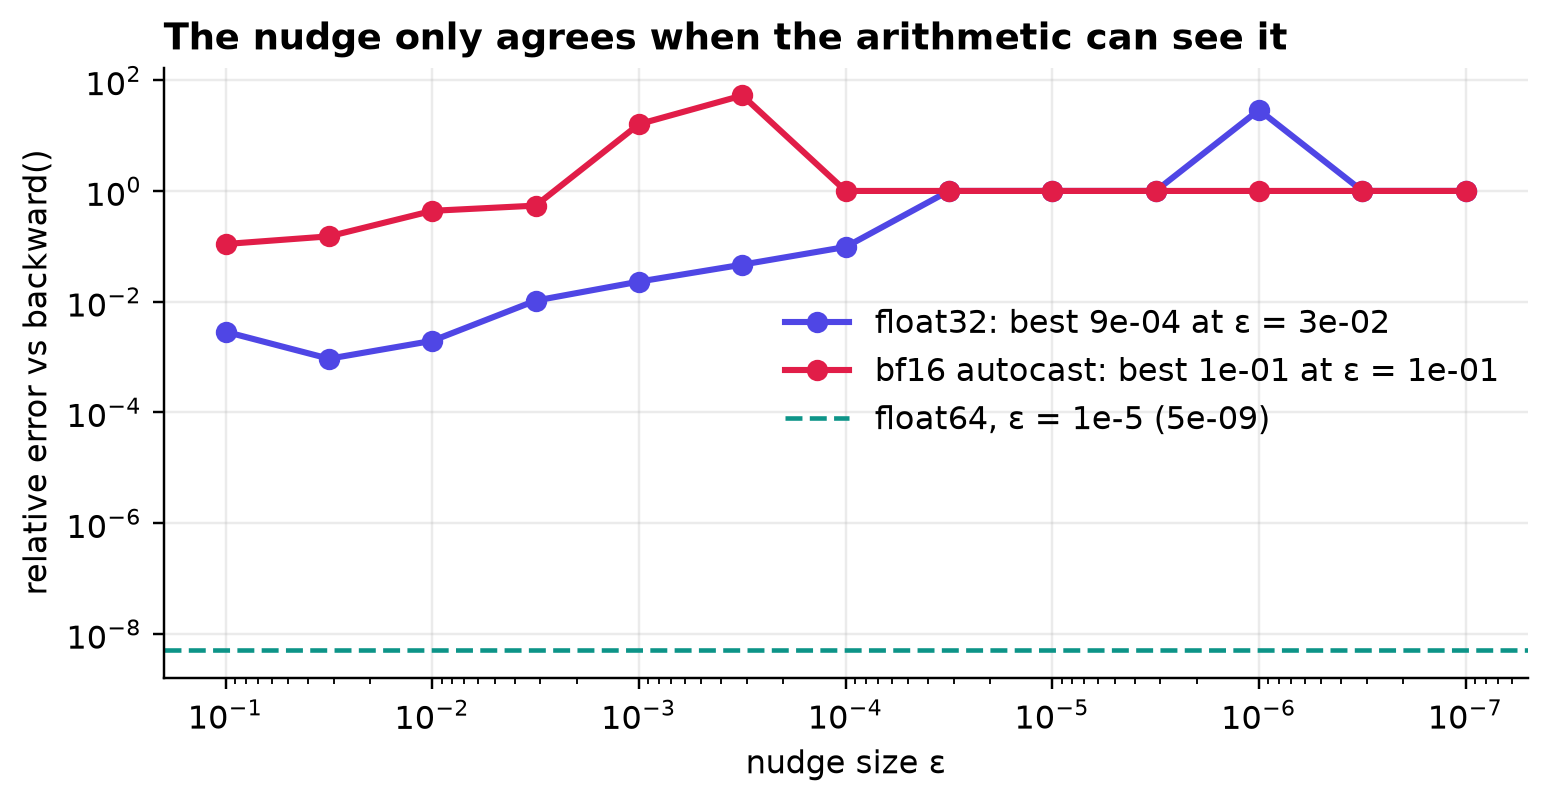

In [ ]:
m32 = copy.deepcopy(m64).float()
eps_grid = np.logspace(-1, -7, 13)
PRECISIONS = {'float32': lambda: torch.autocast(dev, enabled=False), 'bf16 autocast': autocast}


def nudge_loss(model, context, h):
    """(L(w + h) − L(w − h)) / 2h for the chosen fc weight, computed under the given precision."""
    weight = model.blocks[0].fc.weight
    w0 = weight[fc_idx].item()
    losses = []
    with torch.no_grad():
        for sign in (+1, -1):
            weight[fc_idx] = w0 + sign * h
            with context():
                losses.append(F.cross_entropy(model(xb).float().view(-1, V), yb.view(-1)).item())
        weight[fc_idx] = w0
    return losses[0], losses[1], (losses[0] - losses[1]) / (2 * h)


nudge_curves = {
    label: np.array([abs(nudge_loss(m32, context, h)[2] - fc_analytic) / abs(fc_analytic) for h in eps_grid])
    for label, context in PRECISIONS.items()
}

_fig, _ax = plt.subplots(figsize=(8, 3.6))
for (_label, _errors), _color in zip(nudge_curves.items(), (INK, ROSE)):
    _best = _errors.argmin()
    _ax.loglog(eps_grid, np.maximum(_errors, 1e-12), 'o-', color=_color, lw=2,
               label=f'{_label}: best {_errors[_best]:.0e} at ε = {eps_grid[_best]:.0e}')
_ax.axhline(nudge_rows[0][-1], color=TEAL, ls='--', lw=1.5, label=f'float64, ε = 1e-5 ({nudge_rows[0][-1]:.0e})')
_ax.set(xlabel='nudge size ε', ylabel='relative error vs backward()', title='The nudge only agrees when the arithmetic can see it')
_ax.invert_xaxis()
_ax.legend()
save(_fig, 'r1-nudge-precision.png')

In [ ]:
nudge_eps = mo.ui.slider(start=-8, stop=0, step=0.25, value=-3, label='log₁₀ ε', show_value=True)
nudge_precision = mo.ui.dropdown(['float64', 'float32', 'bf16 autocast'], value='float32', label='precision')
mo.vstack([
    mo.md('**Try it.** Pick a nudge size and a precision, and watch which error wins.'),
    mo.hstack([nudge_eps, nudge_precision], justify='start', gap=2),
])

Try it. Pick a nudge size and a precision, and watch which error wins.

In [ ]:
_h = 10 ** nudge_eps.value
if nudge_precision.value == 'float64':
    _lp, _lm, _num = nudge_loss(m64, lambda: torch.autocast(dev, enabled=False), _h)
else:
    _lp, _lm, _num = nudge_loss(m32, PRECISIONS[nudge_precision.value], _h)
_rel = abs(_num - fc_analytic) / abs(fc_analytic)
mo.md(
    f"""
    | ε | L(w + ε) | L(w − ε) | L₊ − L₋ | nudge | `backward()` (float64) | relative error |
    |---|---|---|---|---|---|---|
    | {_h:.1e} | {_lp:.12f} | {_lm:.12f} | {_lp - _lm:.3e} | {_num:.8e} | {fc_analytic:.8e} | **{_rel:.1e}** |
    """
)

| ε | L(w + ε) | L(w − ε) | L₊ − L₋ | nudge | `backward()` (float64) | relative error |
|---|---|---|---|---|---|---|
| 1.0e-03 | 10.994632720947 | 10.994665145874 | -3.242e-05 | -1.62124634e-02 | -1.58476147e-02 | **2.3e-02** |

In [ ]:
def _gradients_add():
    m64.zero_grad()
    loss64().backward()
    first = m64.blocks[0].fc.weight.grad[fc_idx].item()
    loss64().backward()                    # no zero_grad in between
    second = m64.blocks[0].fc.weight.grad[fc_idx].item()
    return first, second


_first, _second = _gradients_add()
mo.md(
    f"""
    **Gradients add; they do not replace.** This is the line from the lecture that surprises people. Calling `backward()`
    twice without `zero_grad()` gives exactly twice the gradient, and nothing raises an error:

    * after one backward: {_first:.10f}
    * after a second: {_second:.10f}
    * ratio: **{_second / _first:.6f}**

    Gradient accumulation relies on this. It is also the bug you get when you forget to clear the gradients.
    """
)

**Gradients add; they do not replace.** This is the line from the lecture that surprises people. Calling `backward()`
twice without `zero_grad()` gives exactly twice the gradient, and nothing raises an error:

* after one backward: -0.0158476147
* after a second: -0.0316952294
* ratio: **2.000000**

Gradient accumulation relies on this. It is also the bug you get when you forget to clear the gradients.

In [ ]:
mo.vstack([
    mo.md(
        r"""
        ## 3 · Breaking gradient accumulation on purpose

        **What and why.** We combine micro-batches the right way and the wrong way, train a model with each, and compare.
        Gradient accumulation is how you train with a batch larger than memory allows, so a silent weighting bug here
        changes what the model learns.

        Each optimiser step here is built from **four micro-batches of different lengths**:

        * 16 stories each, cut to T = 16, 32, 128 and 256 tokens;
        * right-padded (filler tokens added at the end), with the padding masked out of the loss;
        * so real tokens per micro-batch differ by about 10×.

        Two ways to combine them:

        * **correct:** `loss_i = sum of token losses_i / N_total`, so every token in the step gets the same weight;
        * **broken (pre-2024 frameworks):** `loss_i = mean of token losses_i / 4`, the average of averages.
        """
    ),
    figure('03-accumulation.svg'),
])

3 · Breaking gradient accumulation on purpose 
 What and why. We combine micro-batches the right way and the wrong way, train a model with each, and compare.
Gradient accumulation is how you train with a batch larger than memory allows, so a silent weighting bug here
changes what the model learns. 
 Each optimiser step here is built from four micro-batches of different lengths : 
 
 16 stories each, cut to T = 16, 32, 128 and 256 tokens; 
 right-padded (filler tokens added at the end), with the padding masked out of the loss; 
 so real tokens per micro-batch differ by about 10×. 
 
 Two ways to combine them: 
 
 correct: loss_i = sum of token losses_i / N_total , so every token in the step gets the same weight; 
 broken (pre-2024 frameworks): loss_i = mean of token losses_i / 4 , the average of averages. 
 
 Average of averages versus per-token mean 
 
 Who gets a vote: micro-batches or tokens? 
 Lecture example: three micro-batches with 4, 4 and 2 real tokens. Each square is one token's loss. 

 
 mb 1 
 
 mean 2.0 
 mb 2 
 
 mean 2.0 
 mb 3 
 
 mean 5.0 
 dashed = padding, masked out of the loss 
 

 <!-- wrong -->
 
 
 ✗ average of averages (pre-2024 frameworks) 
 (2.0 + 2.0 + 5.0) / 3 = 3.000 
 each micro-batch gets 1/3 of the vote → mb 3's tokens count 2× each 
 
 <!-- right -->
 
 
 ✓ sum of token losses / total tokens 
 (4·2.0 + 4·2.0 + 2·5.0) / 10 = 2.600 
 each token gets 1/10 of the vote, whichever micro-batch it landed in 
 

 
 The fix in code 
 n = Σ valid tokens over ALL micro-batches 
 loss_i = CE(..., reduction='sum') / n 
 loss_i.backward() # grads add up 
 
 +15.4% wrong here, and exactly 0% wrong whenever token counts are equal, 
 which is why casual tests never caught it.

In [ ]:
_n_tok, _means = np.array([4, 4, 2]), np.array([2.0, 2.0, 5.0])   # the lecture's three micro-batches
_right = (_n_tok * _means).sum() / _n_tok.sum()
_wrong = _means.mean()
mo.md(f'**Lecture example:** the correct per-token loss is {_right:.4f}; the average of averages is {_wrong:.4f}, '
      f'**{100 * (_wrong / _right - 1):.1f}% too high**.')

**Lecture example:** the correct per-token loss is 2.6000; the average of averages is 3.0000, **15.4% too high**.

In [ ]:
MB_T, MB_B = (16, 32, 128, 256), 16          # micro-batch lengths, stories per micro-batch


def doc_batch(pool, B, T, gen):
    """B stories, each from its first token, cut to T and right-padded. Padded targets are -100, which the loss ignores."""
    x = torch.full((B, T), EOS, dtype=torch.long)
    y = torch.full((B, T), -100, dtype=torch.long)
    for row, i in enumerate(torch.randint(len(pool), (B,), generator=gen).tolist()):
        story = torch.tensor(pool[i][:T + 1])
        n = len(story) - 1
        x[row, :n] = story[:-1]
        y[row, :n] = story[1:]
    return x.to(dev), y.to(dev)


def step_batches(gen):
    return [doc_batch(train_docs, MB_B, T, gen) for T in MB_T]


def accumulate(model, micro_batches, mode, use_amp=True):
    """Backward over every micro-batch. Returns (true per-token loss, average of the per-micro-batch averages)."""
    n_total = sum(int((y != -100).sum()) for _, y in micro_batches)
    loss_sum, averages = 0.0, []
    for x, y in micro_batches:
        with (autocast() if use_amp else torch.autocast(dev, enabled=False)):
            token_loss_sum = F.cross_entropy(model(x).float().view(-1, V), y.view(-1), ignore_index=-100, reduction='sum')
        n = int((y != -100).sum())
        if mode == 'correct':
            part = token_loss_sum / n_total                     # every real token in the step weighs the same
        else:
            part = (token_loss_sum / n) / len(micro_batches)    # every micro-batch weighs the same
        part.backward()
        loss_sum += token_loss_sum.item()
        averages.append(token_loss_sum.item() / n)
    return loss_sum / n_total, float(np.mean(averages))

In [ ]:
def _compare_gradients():
    """One fixed step in float32: each accumulation mode against the same step run as ONE padded batch."""
    torch.manual_seed(0)
    model = GPT(Cfg()).to(dev)
    micro_batches = step_batches(torch.Generator().manual_seed(3))
    full_x = torch.cat([F.pad(x, (0, 256 - x.shape[1]), value=EOS) for x, _ in micro_batches])
    full_y = torch.cat([F.pad(y, (0, 256 - y.shape[1]), value=-100) for _, y in micro_batches])

    def flat_grad():
        return torch.cat([p.grad.flatten() for p in model.parameters()])

    F.cross_entropy(model(full_x).view(-1, V), full_y.view(-1), ignore_index=-100).backward()
    g_full = flat_grad().clone()
    rows = []
    for mode in ('correct', 'broken'):
        model.zero_grad()
        accumulate(model, micro_batches, mode, use_amp=False)    # float32, so the only difference is the weighting
        g = flat_grad()
        rows.append((mode, ((g - g_full).norm() / g_full.norm()).item(),
                     F.cosine_similarity(g, g_full, dim=0).item(), (g.norm() / g_full.norm()).item()))
    return [int((y != -100).sum()) for _, y in micro_batches], rows


mb_tokens, grad_check = _compare_gradients()
mo.vstack([
    mo.md(f'Real (unpadded) tokens per micro-batch on this step: **{mb_tokens}**'),
    pd.DataFrame(grad_check, columns=['accumulation', '‖g − g_full‖ / ‖g_full‖', 'cosine to full batch', '‖g‖ / ‖g_full‖']
                 ).style.format(precision=6),
    mo.md('**Correct accumulation reproduces the one-big-batch gradient to float32 roundoff; the broken one points '
          'somewhere else.** *Cosine* is the cosine similarity of two gradient vectors: 1 means the same direction. '
          'Next, train both from the same initial weights on the same micro-batches in the same order, and log both '
          'ways of reporting the loss.'),
])

,accumulation,‖g − g_full‖ / ‖g_full‖,cosine to full batch,‖g‖ / ‖g_full‖
0,correct,0.000001,1.000000,1.000000
1,broken,0.464010,0.923895,1.186358


In [ ]:
def held_out_loss(model, val_batches):
    """Per-token held-out loss, split into the first 16 positions of each story and everything after."""
    sums = {'short': 0.0, 'long': 0.0}
    counts = {'short': 0, 'long': 0}
    model.eval()
    with torch.no_grad(), autocast():
        for x, y in val_batches:
            token_loss = F.cross_entropy(model(x).float().view(-1, V), y.view(-1), ignore_index=-100,
                                         reduction='none').view(y.shape)
            real = y != -100
            for part, cols in (('short', slice(None, 16)), ('long', slice(16, None))):
                sums[part] += token_loss[:, cols][real[:, cols]].sum().item()
                counts[part] += real[:, cols].sum().item()
    model.train()
    return sums['short'] / counts['short'], sums['long'] / counts['long']


def accum_run(mode, steps=1000, peak=6e-4, warmup=50, seed=0):
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(42)                    # same micro-batches, same order, for both modes
    model = GPT(Cfg()).to(dev)
    opt = make_opt(model, peak)
    val_gen = torch.Generator().manual_seed(7)
    val_batches = [doc_batch(val_docs, 64, 256, val_gen) for _ in range(4)]

    hist = {'true': [], 'avg_avg': [], 'val_step': [], 'val_short': [], 'val_long': []}
    t_start = time.time()
    for step in range(steps):
        for group in opt.param_groups:
            group['lr'] = lr_at(step, peak, warmup, steps)
        true_loss, avg_of_avgs = accumulate(model, step_batches(gen), mode)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        opt.zero_grad(set_to_none=True)
        hist['true'].append(true_loss)
        hist['avg_avg'].append(avg_of_avgs)
        if step % 50 == 0 or step == steps - 1:
            short, long = held_out_loss(model, val_batches)
            hist['val_step'].append(step)
            hist['val_short'].append(short)
            hist['val_long'].append(long)
    hist['seconds'] = time.time() - t_start
    return {k: np.array(v) for k, v in hist.items()}


ACC = cached('accumulation_runs', lambda: {mode: accum_run(mode) for mode in ('correct', 'broken')})
acc_seconds = sum(float(h['seconds']) for h in ACC.values())
mo.plain(pd.DataFrame({mode: {'train loss, last 50 steps (true per-token)': h['true'][-50:].mean(),
                              'held-out loss, positions < 16': h['val_short'][-1],
                              'held-out loss, positions ≥ 16': h['val_long'][-1]} for mode, h in ACC.items()}).round(4))

,correct,broken
"train loss, last 50 steps (true per-token)",2.0414,2.2596
"held-out loss, positions < 16",1.2379,1.2519
"held-out loss, positions ≥ 16",2.2934,2.5663


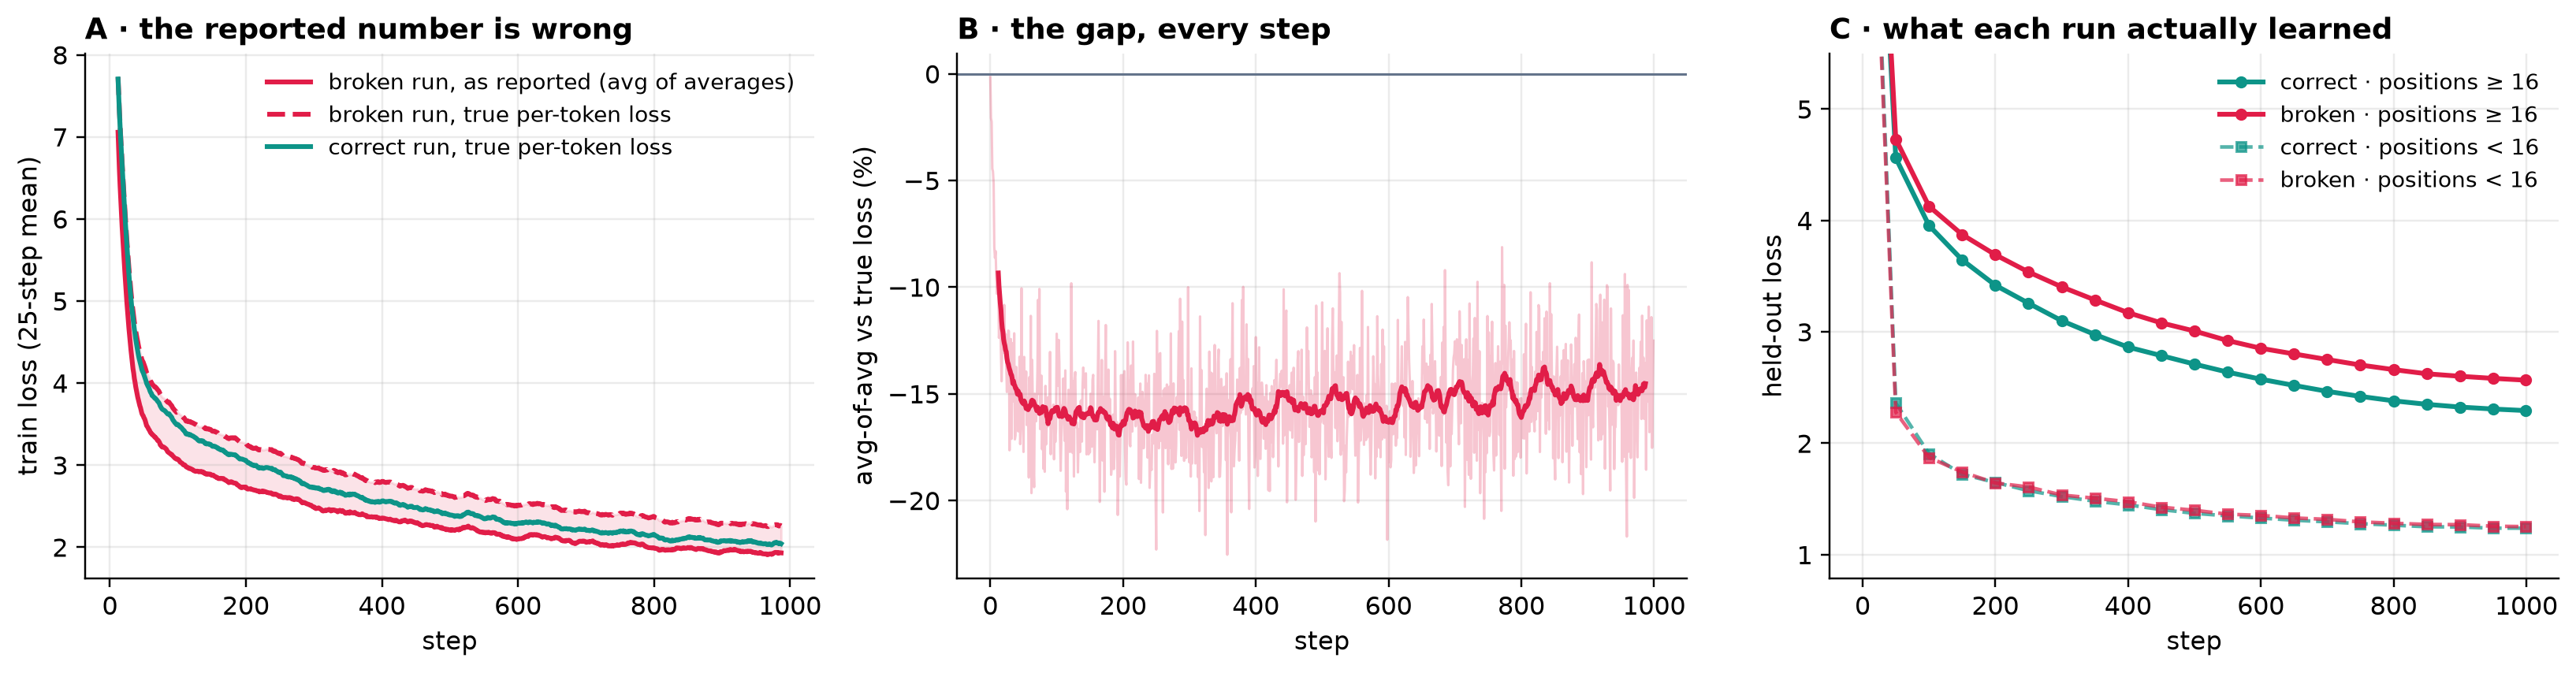

In [ ]:
good, bad = ACC['correct'], ACC['broken']
gap = 100 * (bad['avg_avg'] / bad['true'] - 1)                 # how far the broken run's dashboard is from the truth, %
_x = np.arange(len(smooth(good['true']))) + 12                 # centre of each 25-step window

_fig, _ax = plt.subplots(1, 3, figsize=(15, 4))
_ax[0].plot(_x, smooth(bad['avg_avg']), color=ROSE, lw=2, label='broken run, as reported (avg of averages)')
_ax[0].plot(_x, smooth(bad['true']), color=ROSE, lw=2, ls='--', label='broken run, true per-token loss')
_ax[0].plot(_x, smooth(good['true']), color=TEAL, lw=2, label='correct run, true per-token loss')
_ax[0].fill_between(_x, smooth(bad['true']), smooth(bad['avg_avg']), color=ROSE, alpha=0.12)
_ax[0].set(title='A · the reported number is wrong', xlabel='step', ylabel='train loss (25-step mean)')
_ax[0].legend(fontsize=9)

_ax[1].plot(gap, color=ROSE, alpha=0.25, lw=1)
_ax[1].plot(_x, smooth(gap), color=ROSE, lw=2)
_ax[1].axhline(0, color=SLATE, lw=1)
_ax[1].set(title='B · the gap, every step', xlabel='step', ylabel='avg-of-avg vs true loss (%)')

_vs = good['val_step']
_ax[2].plot(_vs, good['val_long'], 'o-', color=TEAL, lw=2, ms=4, label='correct · positions ≥ 16')
_ax[2].plot(_vs, bad['val_long'], 'o-', color=ROSE, lw=2, ms=4, label='broken · positions ≥ 16')
_ax[2].plot(_vs, good['val_short'], 's--', color=TEAL, lw=1.5, ms=4, alpha=0.7, label='correct · positions < 16')
_ax[2].plot(_vs, bad['val_short'], 's--', color=ROSE, lw=1.5, ms=4, alpha=0.7, label='broken · positions < 16')
_ax[2].set(title='C · what each run actually learned', xlabel='step', ylabel='held-out loss', ylim=(None, 5.5))
_ax[2].legend(fontsize=9)
plt.tight_layout()
save(_fig, 'r2-accumulation.png')

In [ ]:
last100 = slice(-100, None)
_n = np.array(mb_tokens)
_w = np.repeat(1 / (len(_n) * _n), _n)                         # what each real token counts for under the broken rule
acc_stats = {
    'gap_last100': gap[last100].mean(),
    'gap_min': gap.min(),
    'gap_max': gap.max(),
    'catch_up': next((int(s) for s, v in zip(good['val_step'], good['val_long']) if v <= bad['val_long'][-1]), None),
    'short_vs_long': _n[-1] / _n[0],
    'short_vs_correct': _w[0] * _n.sum(),
    'effective': _w.sum() ** 2 / (_w ** 2).sum(),
    'tokens': int(_n.sum()),
}
_g, _b = grad_check
_d_long = bad['val_long'][-1] - good['val_long'][-1]
_d_short = bad['val_short'][-1] - good['val_short'][-1]
_sign = 'too low' if acc_stats['gap_last100'] < 0 else 'too high'
mo.md(
    f"""
    **Broken accumulation reports a loss that is wrong, and trains a model that is worse.**

    * **The gradient.** Correct accumulation matches the one-big-batch gradient to {_g[1]:.1e}, which is float32 roundoff.
      The broken one is **{100 * _b[1]:.0f}% off**, with cosine {_b[2]:.3f} and {_b[3]:.2f}× the length. It points somewhere else.
    * **The sign surprised me.** The lecture example came out 15.4% *too high*. Here the average of averages reads
      **{abs(acc_stats['gap_last100']):.1f}% {_sign}** over the last 100 steps. Every one of the {len(gap)} steps lies between
      {acc_stats['gap_min']:+.1f}% and {acc_stats['gap_max']:+.1f}%. So the broken run's dashboard (panel A, solid red) shows a
      *better* loss than the correct run while it is actually worse.
    * **Why that sign.** It depends on which micro-batches are easy. The T = 16 micro-batch only holds story openings
      ("Once upon a time, there was a little…"), which are very predictable. On the diagnostic step above, the average of
      averages gives its {_n[0]} tokens the same vote as the {_n[-1]:,} tokens of the T = 256 micro-batch. Each short token
      weighs **{acc_stats['short_vs_long']:.1f}×** a long one and **{acc_stats['short_vs_correct']:.1f}×** what it should.
      Easy tokens get over-weighted, so the number looks good. Make the short micro-batches the hard ones and the same bug
      overstates the loss instead. Either way the number is wrong, and you cannot tell which way from the curve.
    * **The damage is real.** Held-out loss at positions ≥ 16 ends at **{bad['val_long'][-1]:.3f} against {good['val_long'][-1]:.3f}**
      ({_d_long:+.3f} nats). The correct run had already reached the broken run's final value by evaluation step
      **{acc_stats['catch_up']}** of {len(good['true'])}. At positions < 16, the part the broken run over-trains on, the gap is only
      {_d_short:+.3f} ({bad['val_short'][-1]:.3f} vs {good['val_short'][-1]:.3f}).
    * **Data thrown away.** The *effective sample size* (Σw)²/Σw² counts how many equally weighted tokens would carry the
      same information as these unequally weighted ones. On the diagnostic step it gives **{acc_stats['effective']:,.0f}
      effective tokens out of {acc_stats['tokens']:,}**: the broken weighting throws away
      {100 * (1 - acc_stats['effective'] / acc_stats['tokens']):.0f}% of each step's data.

    **Takeaway:** normalise by the total number of real tokens in the whole step. Do it once, before the first `backward()`.
    (Both runs together took {acc_seconds:.0f} s.)
    """
)

**Broken accumulation reports a loss that is wrong, and trains a model that is worse.**

* **The gradient.** Correct accumulation matches the one-big-batch gradient to 5.8e-07, which is float32 roundoff.
  The broken one is **46% off**, with cosine 0.924 and 1.19× the length. It points somewhere else.
* **The sign surprised me.** The lecture example came out 15.4% *too high*. Here the average of averages reads
  **14.6% too low** over the last 100 steps. Every one of the 1000 steps lies between
  -22.5% and -0.2%. So the broken run's dashboard (panel A, solid red) shows a
  *better* loss than the correct run while it is actually worse.
* **Why that sign.** It depends on which micro-batches are easy. The T = 16 micro-batch only holds story openings
  ("Once upon a time, there was a little…"), which are very predictable. On the diagnostic step above, the average of
  averages gives its 256 tokens the same vote as the 3,068 tokens of the T = 256 micro-batch. Each short token
  weighs **12.0×** a long one and **5.7×** what it should.
  Easy tokens get over-weighted, so the number looks good. Make the short micro-batches the hard ones and the same bug
  overstates the loss instead. Either way the number is wrong, and you cannot tell which way from the curve.
* **The damage is real.** Held-out loss at positions ≥ 16 ends at **2.566 against 2.293**
  (+0.273 nats). The correct run had already reached the broken run's final value by evaluation step
  **650** of 1000. At positions < 16, the part the broken run over-trains on, the gap is only
  +0.014 (1.252 vs 1.238).
* **Data thrown away.** The *effective sample size* (Σw)²/Σw² counts how many equally weighted tokens would carry the
  same information as these unequally weighted ones. On the diagnostic step it gives **2,397
  effective tokens out of 5,876**: the broken weighting throws away
  59% of each step's data.

**Takeaway:** normalise by the total number of real tokens in the whole step. Do it once, before the first `backward()`.
(Both runs together took 157 s.)

## 4 · The grad norm, every step

**What and why.** We log the grad norm at every step and look for a step where it changed before the loss did. If
the norm warns first, it is a cheap early alarm that a run is heading for trouble.

A normal run first:

* **2,000 steps of 16 × 1,024 tokens** (33M tokens);
* AdamW at peak LR 6e-4, with warmup and cosine decay;
* clipping at 1.0.

The grad norm, measured **before** clipping, is logged at every step along with the loss, the LR and the step time.

In [ ]:
def train_run(steps, peak_lr, warmup, B=16, T=1024, clip=1.0, seed=0):
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(1234)
    model = GPT(Cfg()).to(dev)
    opt = make_opt(model, peak_lr)

    hist = {k: [] for k in ('loss', 'gnorm', 'lr', 'dt')}
    for step in range(steps):
        t0 = time.perf_counter()
        for group in opt.param_groups:
            group['lr'] = lr_at(step, peak_lr, warmup, steps)
        x, y = get_batch('train', B, T, gen)
        with autocast():
            loss = F.cross_entropy(model(x).float().view(-1, V), y.view(-1))
        loss.backward()
        grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
        opt.step()
        opt.zero_grad(set_to_none=True)

        hist['loss'].append(loss.item())                       # .item() waits for the GPU, so dt is honest wall time
        hist['gnorm'].append(grad_norm.item())
        hist['lr'].append(opt.param_groups[0]['lr'])
        hist['dt'].append(time.perf_counter() - t0)
    return model, {k: np.array(v) for k, v in hist.items()}


MAIN_B, MAIN_T = 16, Cfg.block
MAIN = cached('main_run', lambda: train_run(2000, 6e-4, 100, B=MAIN_B, T=MAIN_T)[1])
mo.plain(pd.DataFrame({k: MAIN[k][::250].round(4) for k in ('loss', 'gnorm', 'lr')} | {'ms': (1e3 * MAIN['dt'][::250]).round(1)},
                      index=pd.Index(np.arange(0, 2000, 250), name='step')))

,loss,gnorm,lr,ms
step,,,,
0,10.9584,23.6005,0.0000,91.6
250,3.2412,0.7755,0.0006,89.9
500,2.4889,0.8139,0.0005,89.7
750,2.1134,0.5988,0.0005,89.9
1000,2.0435,0.5898,0.0004,89.8
1250,1.9004,0.5551,0.0002,89.8
1500,1.7254,0.5246,0.0001,89.7
1750,1.5375,0.4944,0.0001,89.9


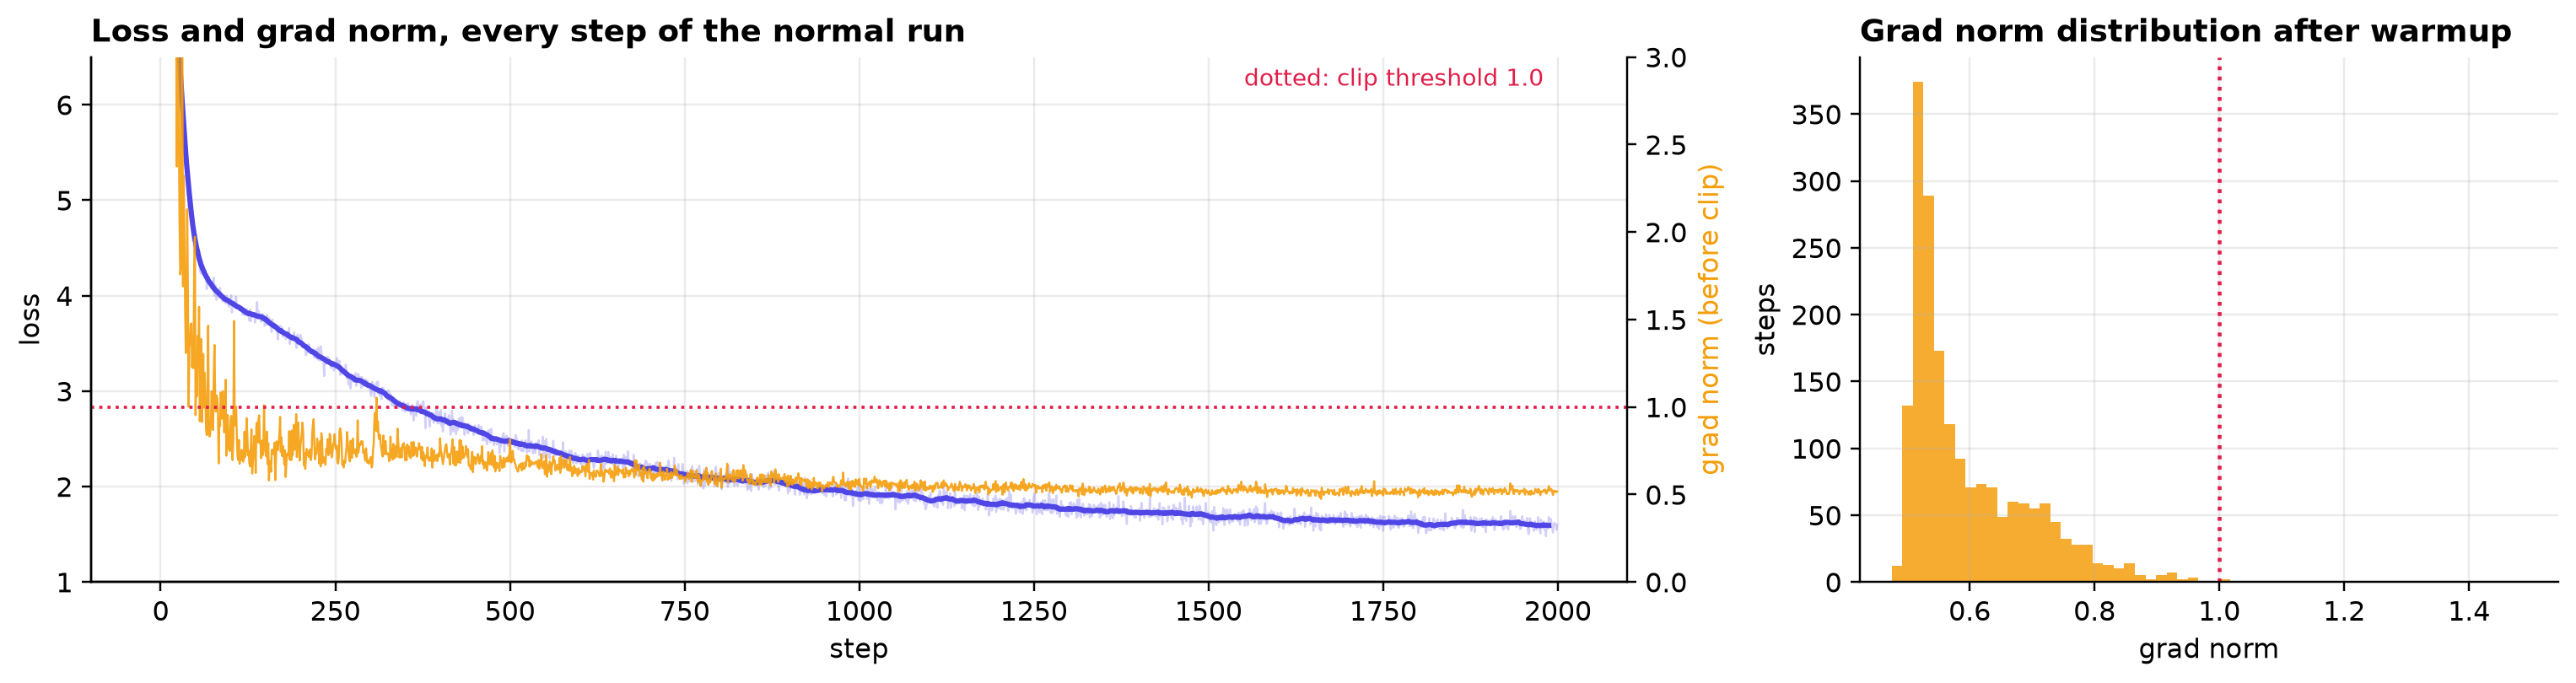

In [ ]:
main_loss, main_gnorm = MAIN['loss'], MAIN['gnorm']
post = main_gnorm[100:]                                        # after warmup
_fig, _ax = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={'width_ratios': [2.2, 1]})
_ax[0].plot(main_loss, color=INK, alpha=0.25, lw=0.8)
_ax[0].plot(np.arange(len(smooth(main_loss))) + 12, smooth(main_loss), color=INK, lw=2, label='loss')
_ax[0].set(xlabel='step', ylabel='loss', title='Loss and grad norm, every step of the normal run', ylim=(1.0, 6.5))
_twin = _ax[0].twinx()
_twin.plot(main_gnorm, color=AMBER, lw=0.8, alpha=0.9, label='grad norm')
_twin.axhline(1.0, color=ROSE, ls=':', lw=1.2)
_twin.set_ylabel('grad norm (before clip)', color=AMBER)
_twin.set_ylim(0, 3)
_twin.grid(False)
_twin.spines['right'].set_visible(True)
_ax[0].text(len(main_loss) * 0.99, 6.2, 'dotted: clip threshold 1.0', ha='right', color=ROSE, fontsize=9)
_ax[1].hist(post, bins=60, color=AMBER, alpha=0.85)
_ax[1].axvline(1.0, color=ROSE, ls=':', lw=1.5)
_ax[1].set(title='Grad norm distribution after warmup', xlabel='grad norm', ylabel='steps')
plt.tight_layout()
save(_fig, 'r3-main-run.png')

In [ ]:
main_stats = {
    'median': np.median(post), 'p95': np.percentile(post, 95), 'p99': np.percentile(post, 99), 'max': post.max(),
    'clipped': 100 * (post > 1).mean(), 'start': main_gnorm[0], 'final_loss': main_loss[-50:].mean(),
}
_top5 = np.sort(np.argsort(post)[-5:] + 100)
mo.md(
    f"""
    After warmup the norm sits in a narrow band: **median {main_stats['median']:.3f}, p95 {main_stats['p95']:.3f},
    p99 {main_stats['p99']:.3f}, max {main_stats['max']:.3f}**. Clipping at 1.0 is active on {main_stats['clipped']:.1f}% of
    post-warmup steps. The five largest norms are at steps {', '.join(f'{s} ({main_gnorm[s]:.2f})' for s in _top5)}. The loss
    falls from {main_loss[0]:.2f} to {main_stats['final_loss']:.3f} (mean of the last 50 steps).

    In a healthy run the norm is boring. It drops from {main_stats['start']:.1f} at initialisation, then sits in a narrow band
    while the loss falls smoothly. Boring is the point. To see the norm *warn* of something, the run has to get into trouble.

    **So the next run is pushed into trouble on purpose:**

    * the learning rate ramps exponentially from 1e-4 to 0.3 over 600 steps;
    * there is **no clipping**;
    * after every update it measures a **probe batch**: one fixed batch of held-out text, the same every time.

    The training loss is noisy because every batch is different text. The probe loss changes only when the weights change.

    **Timing matters for the comparison.**

    * At step *s*, the grad norm and the batch loss come from **the same forward pass**, before update *s*.
    * The probe is measured **after** update *s*.

    So a norm spike at *s* with a normal batch loss at *s* means the gradient already knew something the loss did not.
    """
)

After warmup the norm sits in a narrow band: **median 0.556, p95 0.790,
p99 0.911, max 1.492**. Clipping at 1.0 is active on 0.2% of
post-warmup steps. The five largest norms are at steps 105 (1.49), 108 (1.00), 148 (1.01), 307 (0.97), 309 (1.05). The loss
falls from 10.96 to 1.597 (mean of the last 50 steps).

In a healthy run the norm is boring. It drops from 23.6 at initialisation, then sits in a narrow band
while the loss falls smoothly. Boring is the point. To see the norm *warn* of something, the run has to get into trouble.

**So the next run is pushed into trouble on purpose:**

* the learning rate ramps exponentially from 1e-4 to 0.3 over 600 steps;
* there is **no clipping**;
* after every update it measures a **probe batch**: one fixed batch of held-out text, the same every time.

The training loss is noisy because every batch is different text. The probe loss changes only when the weights change.

**Timing matters for the comparison.**

* At step *s*, the grad norm and the batch loss come from **the same forward pass**, before update *s*.
* The probe is measured **after** update *s*.

So a norm spike at *s* with a normal batch loss at *s* means the gradient already knew something the loss did not.

In [ ]:
def ramp_run(lr0=1e-4, lr1=0.3, steps=600, B=16, T=1024, seed=0):
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(1234)
    model = GPT(Cfg()).to(dev)
    opt = make_opt(model, lr0)
    probe_x, probe_y = get_batch('val', 16, T, torch.Generator().manual_seed(7))

    hist = {k: [] for k in ('loss', 'probe', 'gnorm', 'lr')}
    for step in range(steps):
        lr = lr0 * (lr1 / lr0) ** (step / (steps - 1))          # exponential ramp
        for group in opt.param_groups:
            group['lr'] = lr
        x, y = get_batch('train', B, T, gen)
        with autocast():
            loss = F.cross_entropy(model(x).float().view(-1, V), y.view(-1))
        loss.backward()
        grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), float('inf'))   # measure only, never clip
        opt.step()
        opt.zero_grad(set_to_none=True)
        with torch.no_grad(), autocast():
            probe_loss = F.cross_entropy(model(probe_x).float().view(-1, V), probe_y.view(-1))

        hist['loss'].append(loss.item())
        hist['probe'].append(probe_loss.item())
        hist['gnorm'].append(grad_norm.item())
        hist['lr'].append(lr)
    return {k: np.array(v) for k, v in hist.items()}


def trailing_median(a, s, w=20):
    return np.median(a[max(0, s - w):s])


def trailing_z(a, s, w=20):
    window = a[max(0, s - w):s]
    return (a[s] - window.mean()) / (window.std() + 1e-9)


R = cached('lr_ramp', ramp_run)
gnorm, probe, batch_loss = R['gnorm'], R['probe'], R['loss']
_finite = np.isfinite(gnorm) & np.isfinite(probe) & np.isfinite(batch_loss)
first_nan = int(np.argmin(_finite)) if not _finite.all() else len(gnorm)

# Candidates: the norm is above 2.5x its trailing median while the SAME step's batch loss is unremarkable (z < 1.5).
# Each is scored by how far the probe then climbs over the next 3 updates, relative to its normal step-to-step jitter.
_rows = []
for _s in range(100, first_nan - 4):
    _ratio = gnorm[_s] / trailing_median(gnorm, _s)
    if _ratio > 2.5 and trailing_z(batch_loss, _s) < 1.5:
        _jitter = np.diff(probe[max(0, _s - 30):_s]).std()
        _rise = probe[_s:_s + 3].max() - probe[_s - 1]
        _rows.append((_s, R['lr'][_s], _ratio, trailing_z(batch_loss, _s), _rise, _rise / _jitter))
spike_table = pd.DataFrame(_rows, columns=['step', 'lr', 'norm / trailing median', 'batch-loss z at same step',
                                           'probe rise next 3 updates', 'rise / jitter'])
if len(spike_table):
    spike = int(spike_table.loc[spike_table['rise / jitter'].idxmax(), 'step'])
else:   # nothing passed the filter: fall back to the largest relative jump in the norm
    spike = max(range(100, first_nan - 4), key=lambda s: gnorm[s] / trailing_median(gnorm, s))
mo.vstack([
    mo.md(f'Steps that pass the filter, out of the {first_nan} finite steps. The filter: the norm is more than 2.5× its '
          f'*trailing 20-step median* (the median of the 20 steps just before), while the same step\'s batch loss has a '
          f'*z-score* below 1.5 (it sits less than 1.5 standard deviations above the mean of the previous 20 steps). '
          f'The one whose probe rises most, relative to its jitter, is **step {spike}**.'),
    spike_table.style.format(precision=3).format({'lr': '{:.4f}'}),
])

,step,lr,norm / trailing median,batch-loss z at same step,probe rise next 3 updates,rise / jitter
0,238,0.0024,2.758490,0.732814,0.583070,24.663367
1,476,0.0580,4.247975,1.145332,0.003991,0.066773
2,479,0.0603,6.796886,1.315027,0.211062,3.594002


In [ ]:
zoom_step = mo.ui.slider(start=110, stop=max(111, first_nan - 13), step=1, value=spike, label='zoom on step',
                         show_value=True, full_width=True)
mo.vstack([mo.md(f'**Move the zoom.** It starts on step {spike}, the chosen spike. Drag it to see how ordinary the steps '
                 'around it look.'), zoom_step])

Move the zoom. It starts on step 238, the chosen spike. Drag it to see how ordinary the steps around it look.

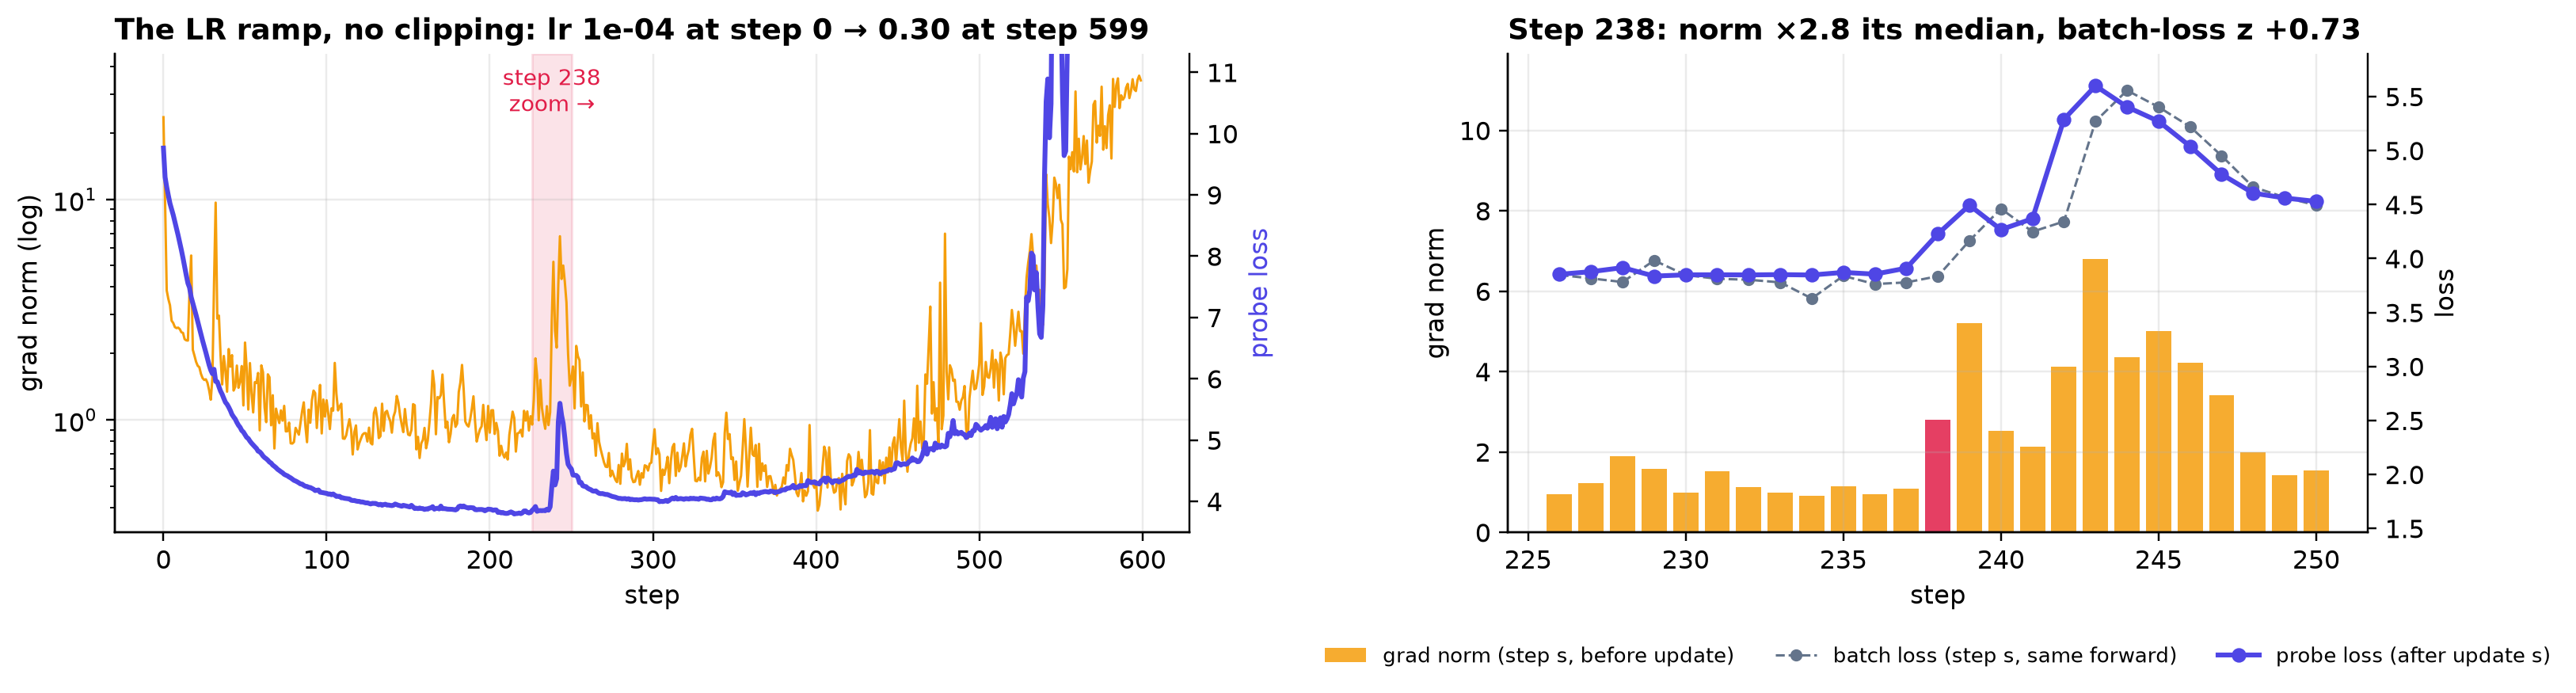

In [ ]:
def _ramp_figure(centre):
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={'width_ratios': [1.25, 1]})
    ok = np.arange(first_nan)
    ax[0].semilogy(ok, gnorm[ok], color=AMBER, lw=1, label='grad norm')
    ax[0].set(xlabel='step', ylabel='grad norm (log)',
              title=f'The LR ramp, no clipping: lr {R["lr"][0]:.0e} at step 0 → {R["lr"][first_nan - 1]:.2f} at step {first_nan - 1}')
    twin = ax[0].twinx()
    twin.plot(ok, probe[ok], color=INK, lw=2, label='probe loss (fixed batch)')
    twin.set_ylabel('probe loss', color=INK)
    twin.set_ylim(np.nanmin(probe[ok]) - 0.3, min(np.nanmax(probe[ok]), 11) + 0.3)
    twin.grid(False)
    twin.spines['right'].set_visible(True)
    ax[0].axvspan(centre - 12, centre + 12, color=ROSE, alpha=0.12)
    ax[0].text(centre, ax[0].get_ylim()[1] * 0.55, f'step {centre}\nzoom →', color=ROSE, ha='center', fontsize=9)

    window = np.arange(centre - 12, min(centre + 13, first_nan))
    ratio = gnorm[centre] / trailing_median(gnorm, centre)
    ax[1].bar(window, gnorm[window], color=[ROSE if s == centre else AMBER for s in window], alpha=0.85, width=0.8,
              label='grad norm (step s, before update)')
    ax[1].set(xlabel='step', ylabel='grad norm', ylim=(0, gnorm[window].max() * 1.75),
              title=f'Step {centre}: norm ×{ratio:.1f} its median, batch-loss z {trailing_z(batch_loss, centre):+.2f}')
    losses = ax[1].twinx()
    losses.plot(window, batch_loss[window], 'o--', color=SLATE, ms=4, lw=1, label='batch loss (step s, same forward)')
    losses.plot(window, probe[window], 'o-', color=INK, ms=5, lw=2, label='probe loss (after update s)')
    lo = min(batch_loss[window].min(), probe[window].min())
    hi = max(batch_loss[window].max(), probe[window].max())
    losses.set_ylim(lo - 1.1 * (hi - lo), hi + 0.15 * (hi - lo))   # losses in the upper band, bars in the lower band
    losses.set_ylabel('loss')
    losses.grid(False)
    losses.spines['right'].set_visible(True)
    h1, l1 = ax[1].get_legend_handles_labels()
    h2, l2 = losses.get_legend_handles_labels()
    losses.legend(h1 + h2, l1 + l2, fontsize=8.5, ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.2))
    plt.tight_layout()
    return fig


if zoom_step.value == spike:
    save(_ramp_figure(spike), 'r4-grad-norm-first.png')
_ramp_figure(zoom_step.value)

In [ ]:
spike_stats = {
    'lr': R['lr'][spike], 'before': gnorm[spike - 1], 'norm': gnorm[spike],
    'ratio': gnorm[spike] / trailing_median(gnorm, spike), 'loss': batch_loss[spike], 'z': trailing_z(batch_loss, spike),
    'probe_before': probe[spike - 1], 'probe_after': probe[spike:spike + 4],
    'rise_over_jitter': spike_table.set_index('step').loc[spike, 'rise / jitter'] if len(spike_table) else float('nan'),
}
_after = ' → '.join(f'{v:.3f}' for v in spike_stats['probe_after'])
mo.md(
    f"""
    **At step {spike} the grad norm jumped while the loss from the same forward pass looked normal; the probe loss rose
    one update later.**

    * **The norm** (lr ≈ {spike_stats['lr']:.4f}): **{spike_stats['before']:.3f} → {spike_stats['norm']:.3f},
      {spike_stats['ratio']:.1f}× its trailing median**.
    * **The batch loss** from that *same* forward pass: {spike_stats['loss']:.3f}, an ordinary value (z = {spike_stats['z']:+.2f}
      against the previous 20 steps). Nothing in the loss says anything is wrong.
    * **The probe loss** after the update made from that gradient: **{spike_stats['probe_before']:.3f} → {spike_stats['probe_after'][0]:.3f}**,
      a rise of {spike_stats['rise_over_jitter']:.1f}× its normal step-to-step jitter. After that it reads {_after}, but those later
      values also include updates {spike + 1} onward, whose own norms were large too ({gnorm[spike + 1]:.2f} at step {spike + 1}).

    **Be precise about what this shows.**

    * The lead is one update. The norm is abnormal at step *s*; the loss only moves once update *s* has been applied, and
      that update is what causes the rise.
    * The step was chosen after the fact, as the best of the candidates in the table.
    * With clipping at 1.0, AdamW would have received that gradient scaled by {1 / spike_stats['norm']:.2f}.
    """
)

**At step 238 the grad norm jumped while the loss from the same forward pass looked normal; the probe loss rose
one update later.**

* **The norm** (lr ≈ 0.0024): **1.081 → 2.806,
  2.8× its trailing median**.
* **The batch loss** from that *same* forward pass: 3.836, an ordinary value (z = +0.73
  against the previous 20 steps). Nothing in the loss says anything is wrong.
* **The probe loss** after the update made from that gradient: **3.911 → 4.228**,
  a rise of 24.7× its normal step-to-step jitter. After that it reads 4.228 → 4.494 → 4.268 → 4.369, but those later
  values also include updates 239 onward, whose own norms were large too (5.21 at step 239).

**Be precise about what this shows.**

* The lead is one update. The norm is abnormal at step *s*; the loss only moves once update *s* has been applied, and
  that update is what causes the rise.
* The step was chosen after the fact, as the best of the candidates in the table.
* With clipping at 1.0, AdamW would have received that gradient scaled by 0.36.

**Is that a one-update lead, or a real warning?** The lecture's stronger claim is that the norm warns *many* steps
early. The next cell tests that over the whole run-up to divergence. The rule itself is causal (each step only looks
backwards), but two choices were made after seeing this run: where the scan starts (the probe-loss low point after
the earlier spike recovers) and the settings below. So treat the result as one run's evidence, not a benchmark.

**The detector**, at each step:

* takes the median of the last 5 values of the signal;
* compares it with the median and spread of the previous 50 steps. The spread is the **MAD** (median absolute
  deviation), scaled by 1.4826 into a **robust SD**: a standard deviation that one outlier cannot inflate;
* fires once the recent median sits more than 3 robust SDs above for 5 steps in a row.

The same detector, with the same settings, runs on the grad norm (in log space), the probe loss and the batch loss.
Then the spike filter runs on the normal 2,000-step run. That run has no probe batch, so the next 3 batch losses stand
in for it.

In [ ]:
def onset(signal, start, w=50, k=3.0, hold=5, smooth_w=5):
    """First step >= start where the 5-step median beats the trailing 50-step median by k robust SDs, `hold` steps running."""
    run = 0
    for s in range(max(start, w + smooth_w), len(signal)):
        baseline = signal[s - smooth_w - w:s - smooth_w]
        median = np.median(baseline)
        robust_sd = 1.4826 * np.median(np.abs(baseline - median)) + 1e-9
        recent = np.median(signal[s - smooth_w + 1:s + 1])
        run = run + 1 if (recent - median) / robust_sd > k else 0
        if run == hold:
            return s - hold + 1
    return None


_fin = slice(0, first_nan)
probe_min = int(np.argmin(probe[_fin]))
# The step-238 spike recovers. Test the final divergence from the lowest probe loss AFTER that recovery,
# and call the run "blown up" once the probe loss is worse than the untrained model's.
settle = spike + 20 + int(np.argmin(probe[spike + 20:first_nan]))
blowup = int(np.argmax(probe[_fin] > probe[0])) if (probe[_fin] > probe[0]).any() else first_nan
_edges = np.linspace(settle, blowup, 5).astype(int)            # four equal windows from the recovery to the blow-up
ramp_windows = pd.DataFrame(
    [(f'{a}–{b}', f'{R["lr"][a]:.3f}–{R["lr"][b - 1]:.3f}', np.median(gnorm[a:b]), probe[a:b].mean(), batch_loss[a:b].mean())
     for a, b in zip(_edges[:-1], _edges[1:])],
    columns=['steps', 'lr', 'median grad norm', 'mean probe loss', 'mean batch loss'])

_signals = {'grad norm (log)': np.log(gnorm), 'probe loss': probe, 'batch loss': batch_loss}
onsets = {name: onset(sig[_fin], settle) for name, sig in _signals.items()}

main_hits = []
for _s in range(120, len(main_gnorm) - 4):
    _ratio = main_gnorm[_s] / trailing_median(main_gnorm, _s)
    if _ratio > 2.5 and trailing_z(main_loss, _s) < 1.5:
        main_hits.append((_s, _ratio, trailing_z(main_loss, _s), main_loss[_s + 1:_s + 4].mean() - main_loss[_s - 20:_s].mean()))
main_max_ratio = max(main_gnorm[s] / trailing_median(main_gnorm, s) for s in range(120, len(main_gnorm)))

mo.vstack([
    mo.md(f'After the step-{spike} spike the probe loss recovers to its lowest point at step **{settle}** '
          f'({probe[settle]:.3f}, lr {R["lr"][settle]:.3f}). It then climbs, and at step **{blowup}** it passes the untrained '
          f'model\'s loss ({probe[0]:.2f}): the run has blown up. '
          + ('' if first_nan < len(gnorm) else 'No step went NaN: with AdamW the update size is bounded, so the run gets '
             'worse and worse without ever overflowing.')),
    ramp_windows.style.format(precision=3),
    mo.plain(pd.DataFrame([(name, s, (blowup - s) if s is not None else None) for name, s in onsets.items()],
                          columns=['detector on', 'first fires at step', 'steps before the blow-up'])),
    mo.md(f'Normal run: **{len(main_hits)}** steps pass the spike filter; the largest norm / trailing median after step 120 '
          f'is **{main_max_ratio:.2f}×**.'),
])

After the step-238 spike the probe loss recovers to its lowest point at step 304 (3.994, lr 0.006). It then climbs, and at step 541 it passes the untrained model's loss (9.76): the run has blown up. No step went NaN: with AdamW the update size is bounded, so the run gets worse and worse without ever overflowing. 
 
 
 
   
 steps 
 lr 
 median grad norm 
 mean probe loss 
 mean batch loss 
 
 
 
 
 0 
 304–363 
 0.006–0.013 
 0.670 
 4.066 
 4.013 
 
 
 1 
 363–422 
 0.013–0.028 
 0.516 
 4.257 
 4.229 
 
 
 2 
 422–481 
 0.028–0.061 
 0.739 
 4.629 
 4.615 
 
 
 3 
 481–541 
 0.062–0.136 
 1.841 
 5.767 
 5.684 
 
 
 
 detector on first fires at step steps before the blow-up 0 grad norm (log) 469 72 1 probe loss 345 196 2 batch loss 525 16 Normal run: 0 steps pass the spike filter; the largest norm / trailing median after step 120 is 1.48× .

In [ ]:
_on = onsets
_norm, _probe, _batch = _on['grad norm (log)'], _on['probe loss'], _on['batch loss']
mo.md(
    f"""
    **The grad norm is an early warning compared with the batch loss, but a fixed probe batch warned earlier still.**

    * **Inside one step, it moved first.** At step {spike} the norm was {spike_stats['ratio']:.1f}× normal while that step's
      loss looked ordinary. The loss moved one update later, climbed for about five steps, and then took ~20 steps to
      recover (panel on the right above). If the job had been watching the norm, this was the step to look at.
    * **Over the slow run-up, it beat the loss I would actually have.** A real run has no probe batch: it only sees the
      noisy batch loss. On that signal the detector fired at step **{_batch}**. On the grad norm it fired at step
      **{_norm}**, **{_batch - _norm} steps earlier** and {blowup - _norm} steps before the blow-up.
    * **But it was not the earliest signal.** The noise-free probe loss fired at step **{_probe}**, {_norm - _probe} steps
      before the norm. The loss on a fixed batch rose slowly long before the gradient got large. So the honest summary:
      the grad norm is a cheap, early warning compared with the batch loss. A fixed held-out batch measured every few
      steps is cheaper still and earlier.
    * **In the healthy run it is boring.** {len(main_hits)} steps out of 2,000 pass the spike filter, and the largest
      jump is {main_max_ratio:.2f}× the trailing median. A norm that sits in a narrow band is what "nothing is wrong" looks
      like, which is exactly why a jump stands out.
    """
)

**The grad norm is an early warning compared with the batch loss, but a fixed probe batch warned earlier still.**

* **Inside one step, it moved first.** At step 238 the norm was 2.8× normal while that step's
  loss looked ordinary. The loss moved one update later, climbed for about five steps, and then took ~20 steps to
  recover (panel on the right above). If the job had been watching the norm, this was the step to look at.
* **Over the slow run-up, it beat the loss I would actually have.** A real run has no probe batch: it only sees the
  noisy batch loss. On that signal the detector fired at step **525**. On the grad norm it fired at step
  **469**, **56 steps earlier** and 72 steps before the blow-up.
* **But it was not the earliest signal.** The noise-free probe loss fired at step **345**, 124 steps
  before the norm. The loss on a fixed batch rose slowly long before the gradient got large. So the honest summary:
  the grad norm is a cheap, early warning compared with the batch loss. A fixed held-out batch measured every few
  steps is cheaper still and earlier.
* **In the healthy run it is boring.** 0 steps out of 2,000 pass the spike filter, and the largest
  jump is 1.48× the trailing median. A norm that sits in a narrow band is what "nothing is wrong" looks
  like, which is exactly why a jump stands out.

In [ ]:
mo.vstack([
    mo.md(
        r"""
        ## 5 · MFU, measured honestly

        **What and why.** We measure how much of the GPU's arithmetic the training run actually used, and find where the
        rest went. Training cost is GPU time, so every point of MFU lost is time and money spent on nothing.

        MFU divides the arithmetic the model *needed* by what the chip *could* have done in the same time.

        **The numerator** uses 6N FLOPs per token (2N forward, 4N backward), plus the attention-score term 12·L·T·C that 6N
        leaves out.

        * N counts every parameter except the position table (that is the matmul weights plus ~0.1M biases and layernorm gains).
        * The tied `wte` counts once, because it is the head.
        * The position table does not count, because it is a lookup, not a matmul.

        **The denominator needs care.**

        * NVIDIA's whitepaper gives **503.8 TFLOP/s** dense bf16 for the RTX PRO 6000 Blackwell *Workstation* card, at its
          2,617 MHz boost clock.
        * That works out to 503.8 × 10¹² / (188 SMs × 2.617 × 10⁹) = **1,024 bf16 FLOPs per clock per SM** (an SM, streaming
          multiprocessor, is one of the GPU's compute units).
        * This card is the *Server* edition, and `nvidia-smi` caps its SM clock lower. So its real peak is
          188 × 1,024 × its max clock.

        I report MFU against both numbers.
        """
    ),
    figure('04-mfu.svg'),
])

5 · MFU, measured honestly 
 What and why. We measure how much of the GPU's arithmetic the training run actually used, and find where the
rest went. Training cost is GPU time, so every point of MFU lost is time and money spent on nothing. 
 MFU divides the arithmetic the model needed by what the chip could have done in the same time. 
 The numerator uses 6N FLOPs per token (2N forward, 4N backward), plus the attention-score term 12·L·T·C that 6N
leaves out. 
 
 N counts every parameter except the position table (that is the matmul weights plus ~0.1M biases and layernorm gains). 
 The tied wte counts once, because it is the head. 
 The position table does not count, because it is a lookup, not a matmul. 
 
 The denominator needs care. 
 
 NVIDIA's whitepaper gives 503.8 TFLOP/s dense bf16 for the RTX PRO 6000 Blackwell Workstation card, at its
 2,617 MHz boost clock. 
 That works out to 503.8 × 10¹² / (188 SMs × 2.617 × 10⁹) = 1,024 bf16 FLOPs per clock per SM (an SM, streaming
 multiprocessor, is one of the GPU's compute units). 
 This card is the Server edition, and nvidia-smi caps its SM clock lower. So its real peak is
 188 × 1,024 × its max clock. 
 
 I report MFU against both numbers. 
 Where 6N comes from, and what MFU divides by 
 
 6N: the cost of one token, forward and back 
 Every weight is one multiply-add (2 FLOPs) per token on the way forward, and twice that on the way back. 

 
 
 forward 2N 
 y = W·x 
 
 backward: input grad 2N 
 ∂L/∂x = Wᵀ·∂L/∂y 
 
 backward: weight grad 2N 
 ∂L/∂W = ∂L/∂y·xᵀ 
 = 6N 
 + 12·L·T·C for 
 attention scores 
 

 
 MFU = what the model needed ÷ what the chip could do 
 MFU = (6N + 12·L·T·C) × tokens/s 
 
 peak FLOP/s of the chip 
 Counts only useful model math. Recomputation, casts, softmax, optimizer and idle time are all overhead. 
 
 
 
 Why the loss curve can't tell you 
 Same tokens, same updates, same curve at 
 8% or 45%. MFU only changes the bill 
 and the calendar, so it has to be measured, 
 never inferred from the loss.

In [ ]:
N_MM = N_TOTAL - Cfg.block * Cfg.n_embd                       # every matmul weight; the position table is a lookup
L_, C_ = Cfg.n_layer, Cfg.n_embd
flops_tok = 6 * N_MM + 12 * L_ * MAIN_T * C_
step_s = np.median(MAIN['dt'][100:])                           # median step time after warmup
tok_per_s = MAIN_B * MAIN_T / step_s
PEAK_SHEET = 503.8e12                                          # whitepaper, Workstation edition at 2,617 MHz
PEAK = GPU['sms'] * 1024 * GPU['max_sm_mhz'] * 1e6             # same SMs, this card's own clock cap
mfu = flops_tok * tok_per_s / PEAK


def bench(shapes, iters=30, dtype=torch.bfloat16):
    """Achieved FLOP/s over a list of (m, k, n, count) matmuls, timed together the way they run in a step."""
    ops = [(torch.randn(m, k, device=dev, dtype=dtype), torch.randn(k, n, device=dev, dtype=dtype), count)
           for m, k, n, count in shapes]
    flops = sum(2 * a.shape[0] * a.shape[1] * b.shape[1] * count for a, b, count in ops)
    for a, b, _ in ops:                                        # warm up cuBLAS heuristics
        for _ in range(5):
            a @ b
    sync()
    t0 = time.perf_counter()
    for _ in range(iters):
        for a, b, count in ops:
            for _ in range(count):
                a @ b
    sync()
    return flops * iters / (time.perf_counter() - t0)


# Every matmul of one training step at B·T = 16,384 tokens: forward (x·W), input-grad (dY·Wᵀ), weight-grad (Xᵀ·dY).
BT = MAIN_B * MAIN_T
_layers = [(C_, 3 * C_, L_), (C_, C_, L_), (C_, 4 * C_, L_), (4 * C_, C_, L_), (C_, V, 1)]   # (in, out, how many)
step_shapes = [shape for d_in, d_out, n in _layers
               for shape in ((BT, d_in, d_out, n), (BT, d_out, d_in, n), (d_in, BT, d_out, n))]
square, model_mm = cached('matmul_bench', lambda: ({n: bench([(n, n, n, 1)]) for n in (4096, 8192, 16384)}, bench(step_shapes)))

mfu_rows = [
    ('N (matmul parameters)', f'{N_MM:,}'),
    ('FLOPs per token = 6N + 12·L·T·C', f'{flops_tok / 1e6:.1f} M  (attention adds {12 * L_ * MAIN_T * C_ / (6 * N_MM) * 100:.1f}%)'),
    ('median step time (after warmup)', f'{step_s * 1e3:.1f} ms'),
    ('tokens per second', f'{tok_per_s:,.0f}'),
    ('model FLOP/s achieved', f'{flops_tok * tok_per_s / 1e12:.1f} TFLOP/s'),
    (f'peak at this card\'s {GPU["max_sm_mhz"]:.0f} MHz cap (188 × 1,024 × clock)', f'{PEAK / 1e12:.1f} TFLOP/s'),
    ('**MFU vs this card\'s peak**', f'**{100 * mfu:.1f}%**'),
    ('MFU vs the 503.8 TFLOP/s whitepaper figure', f'{100 * flops_tok * tok_per_s / PEAK_SHEET:.1f}%'),
]
mfu_rows += [(f'square bf16 matmul {n}³, benchmarked alone', f'{v / 1e12:.0f} TFLOP/s = {100 * v / PEAK:.0f}% of peak')
             for n, v in square.items()]
mfu_rows += [("this model's own step matmuls, benchmarked alone", f'{model_mm / 1e12:.0f} TFLOP/s = {100 * model_mm / PEAK:.0f}% of peak')]
mo.plain(pd.DataFrame(mfu_rows, columns=['quantity', 'value']).set_index('quantity'))

,value
quantity,
N (matmul parameters),"123,689,472"
FLOPs per token = 6N + 12·L·T·C,855.4 M (attention adds 15.3%)
median step time (after warmup),89.9 ms
tokens per second,"182,343"
model FLOP/s achieved,156.0 TFLOP/s
...,...
MFU vs the 503.8 TFLOP/s whitepaper figure,31.0%
"square bf16 matmul 4096³, benchmarked alone",362 TFLOP/s = 77% of peak
"square bf16 matmul 8192³, benchmarked alone",407 TFLOP/s = 87% of peak


**Where the time goes.** A *kernel* is one function the GPU runs, such as one matmul or one softmax. Below is a CUDA
profile of five training steps, with every kernel sorted by what it does. Only the first bar is work that MFU counts.

Then two more measurements:

* the SM clock and power, sampled from `nvidia-smi`, once while training and once while running nothing but this
  model's matmuls;
* three levers, timed: a bigger batch, `torch.compile` (which compiles the model and fuses small kernels together),
  and leaving the cross-entropy in bf16 instead of upcasting the logits to fp32.

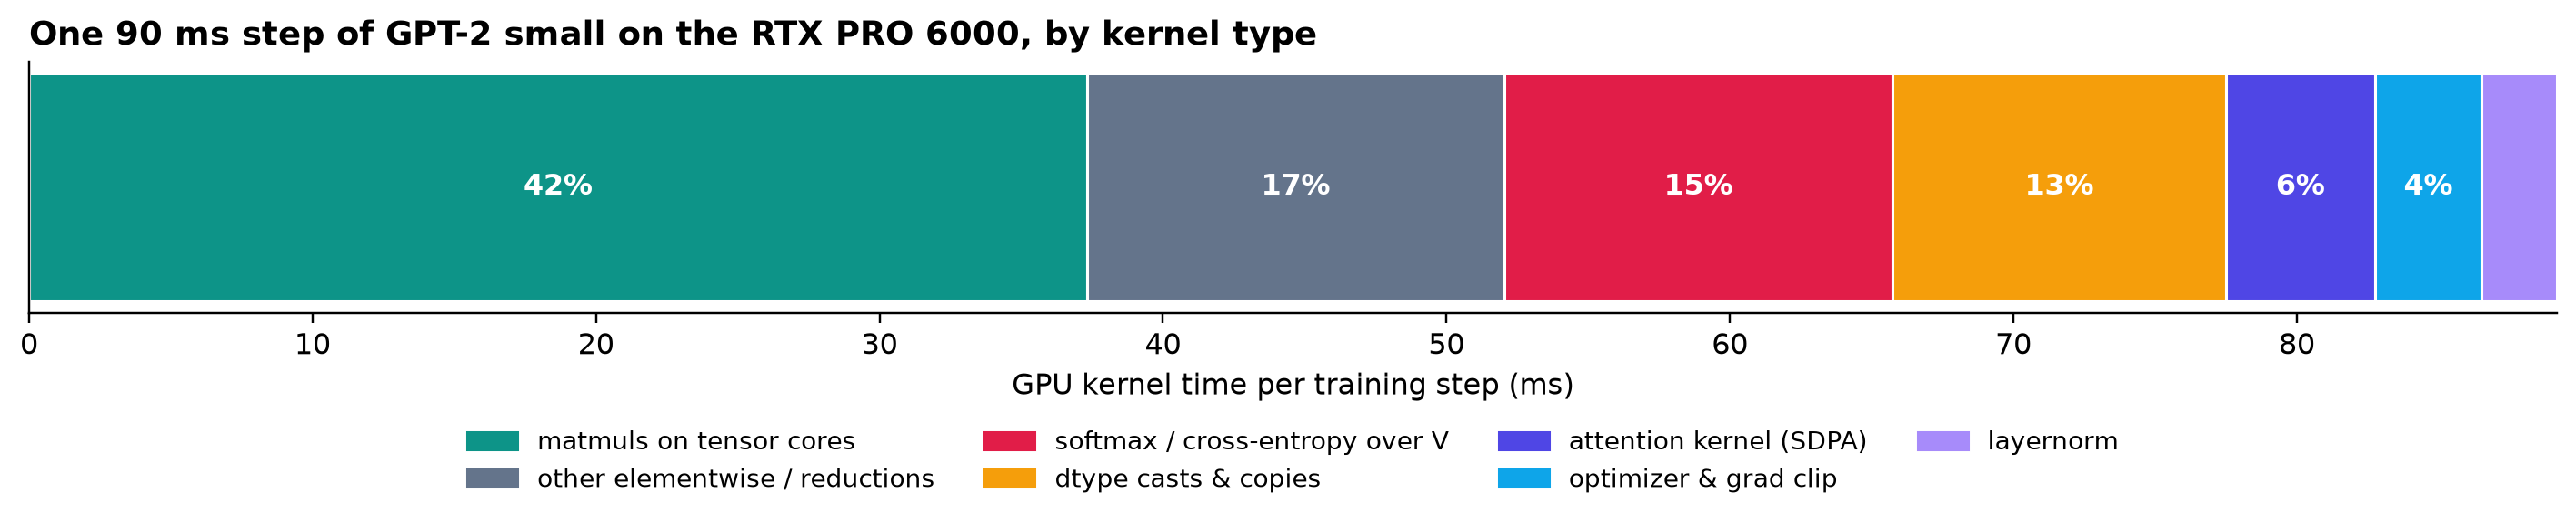

In [ ]:
from torch.profiler import ProfilerActivity, profile


def one_step(model, opt, B=MAIN_B, ce_fp32=True):
    x, y = get_batch('train', B, MAIN_T)
    with autocast():
        logits = model(x)
        logits = logits.float() if ce_fp32 else logits
        loss = F.cross_entropy(logits.view(-1, V), y.view(-1))
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step()
    opt.zero_grad(set_to_none=True)
    return loss


def time_steps(model, opt, B=MAIN_B, n=20, ce_fp32=True):
    for _ in range(5):
        one_step(model, opt, B, ce_fp32)
    sync()
    t0 = time.perf_counter()
    for _ in range(n):
        one_step(model, opt, B, ce_fp32)
    sync()
    return (time.perf_counter() - t0) / n


def bucket(kernel):
    k = kernel.lower()
    if 'fmha' in k or 'attention' in k or 'flash' in k:
        return 'attention kernel (SDPA)'
    if 'gemm' in k or 'cutlass' in k or 'xmma' in k or 'nvjet' in k:
        return 'matmuls on tensor cores'
    if 'softmax' in k or 'nll' in k or 'log_softmax' in k:
        return 'softmax / cross-entropy over V'
    if 'copy' in k or 'cat' in k:
        return 'dtype casts & copies'
    if 'multi_tensor' in k or 'adam' in k or 'norm' in k and 'layer' not in k:
        return 'optimizer & grad clip'
    if 'layer_norm' in k:
        return 'layernorm'
    return 'other elementwise / reductions'


def clocks_during(work):
    """Run work() while sampling nvidia-smi; return (result, median SM MHz, median watts)."""
    samples, stop = [], threading.Event()

    def poll():
        while not stop.is_set():
            out = subprocess.run(['nvidia-smi', '--query-gpu=clocks.sm,power.draw', '--format=csv,noheader,nounits'],
                                 capture_output=True, text=True).stdout
            samples.append([float(v) for v in out.split(',')])
            time.sleep(0.2)

    thread = threading.Thread(target=poll)
    thread.start()
    try:
        result = work()
    finally:
        stop.set()
        thread.join()
    clock, watts = np.median(np.array(samples[2:] or samples), axis=0)   # skip the ramp-up samples
    return result, clock, watts


def _profile():
    torch.manual_seed(0)
    model = GPT(Cfg()).to(dev)
    opt = make_opt(model, 3e-4)
    for _ in range(3):
        one_step(model, opt)
    with profile(activities=[ProfilerActivity.CUDA]) as prof:
        for _ in range(5):
            one_step(model, opt)
        sync()
    kernels = [(e.key, e.self_device_time_total / 5 / 1e3, e.count // 5) for e in prof.key_averages()
               if e.self_device_time_total > 0]

    _, train_mhz, train_w = clocks_during(lambda: time_steps(model, opt, n=80))
    _, mm_mhz, mm_w = clocks_during(lambda: bench(step_shapes, iters=60))

    variants = [('eager, B=16, fp32 loss (the run in §4)', time_steps(model, opt, 16), 16),
                ('eager, B=32, fp32 loss', time_steps(model, opt, 32), 32),
                ('eager, B=16, bf16 loss', time_steps(model, opt, 16, ce_fp32=False), 16)]
    compiled = torch.compile(model)
    t0 = time.time()
    one_step(compiled, opt)
    compile_s = time.time() - t0
    variants += [('torch.compile, B=16, fp32 loss', time_steps(compiled, opt, 16), 16),
                 ('torch.compile, B=32, fp32 loss', time_steps(compiled, opt, 32), 32)]
    peak_gb = torch.cuda.max_memory_allocated() / 1e9
    del model, compiled, opt
    torch.cuda.empty_cache()
    return dict(kernels=kernels, train_mhz=train_mhz, train_w=train_w, mm_mhz=mm_mhz, mm_w=mm_w,
                variants=variants, compile_s=compile_s, peak_gb=peak_gb)


PROF = cached('mfu_profile', _profile)
per_bucket = {}
for _key, _ms, _ in PROF['kernels']:
    per_bucket[bucket(_key)] = per_bucket.get(bucket(_key), 0) + _ms
breakdown = pd.Series(per_bucket).sort_values(ascending=False)
gpu_ms = breakdown.sum()
_order = ['matmuls on tensor cores'] + [k for k in breakdown.index if k != 'matmuls on tensor cores']
_colors = {'matmuls on tensor cores': TEAL, 'softmax / cross-entropy over V': ROSE, 'dtype casts & copies': AMBER,
           'attention kernel (SDPA)': INK, 'optimizer & grad clip': SKY, 'layernorm': '#A78BFA',
           'other elementwise / reductions': SLATE}

_fig, _ax = plt.subplots(figsize=(13, 3.2))
_left = 0
for _k in _order:
    _w = breakdown[_k]
    _ax.barh(0, _w, left=_left, color=_colors[_k], edgecolor='white')
    if _w / gpu_ms > 0.04:
        _ax.text(_left + _w / 2, 0, f'{100 * _w / gpu_ms:.0f}%', ha='center', va='center', color='white', fontweight='bold')
    _left += _w
_ax.set(xlim=(0, gpu_ms), yticks=[], xlabel='GPU kernel time per training step (ms)',
        title=f'One {step_s * 1e3:.0f} ms step of GPT-2 small on the RTX PRO 6000, by kernel type')
_ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=_colors[k]) for k in _order], labels=_order, ncol=4, fontsize=9,
           loc='upper center', bbox_to_anchor=(0.5, -0.38))
_ax.grid(False)
plt.tight_layout()
save(_fig, 'r5-step-breakdown.png')

In [ ]:
mm_ms = breakdown['matmuls on tensor cores']
mm_share = mm_ms / (step_s * 1e3)
mm_rate = 6 * N_MM * BT / (mm_ms / 1e3)
top_kernels = sorted(((ms, calls, bucket(k), k[:80]) for k, ms, calls in PROF['kernels']), reverse=True)[:12]
variant_rows = [(name, t * 1e3, b * MAIN_T / t, 100 * flops_tok * b * MAIN_T / t / PEAK) for name, t, b in PROF['variants']]
mo.vstack([
    mo.hstack([
        mo.plain(pd.DataFrame({'ms / step': breakdown.round(2), 'share': (100 * breakdown / gpu_ms).round(1)})),
        mo.plain(pd.DataFrame(variant_rows, columns=['variant', 'ms / step', 'tokens / s', 'MFU %']).set_index('variant').round(1)),
    ], justify='start', gap=2),
    mo.md(f"""
* GPU busy **{gpu_ms:.1f} ms** of a {step_s * 1e3:.1f} ms step ({100 * gpu_ms / (step_s * 1e3):.0f}%).
* The step's 6N matmul FLOPs ({6 * N_MM * BT / 1e12:.2f} TFLOP) ran in the matmul bucket's {mm_ms:.1f} ms, which is
  **{mm_rate / 1e12:.0f} TFLOP/s** ({100 * mm_rate / PEAK:.0f}% of peak) while training.
* MFU ≈ matmul share × matmul rate / peak = {mm_share:.3f} × {mm_rate / 1e12:.0f} / {PEAK / 1e12:.0f} = **{100 * mm_share * mm_rate / PEAK:.1f}%**
  (measured directly: {100 * mfu:.1f}%).
* SM clock while training: **{PROF['train_mhz']:.0f} MHz at {PROF['train_w']:.0f} W**; while running only the matmuls:
  {PROF['mm_mhz']:.0f} MHz at {PROF['mm_w']:.0f} W. Cap {GPU['max_sm_mhz']:.0f} MHz, {GPU['power_limit_w']:.0f} W.
* `torch.compile` took {PROF['compile_s']:.0f} s the first time; peak memory {PROF['peak_gb']:.1f} GB of {GPU['memory_gb']:.0f} GB.
"""),
    mo.md('**The twelve most expensive kernels**'),
    pd.DataFrame(top_kernels, columns=['ms / step', 'calls / step', 'bucket', 'kernel']).style.format({'ms / step': '{:.2f}'}),
])

ms / step share matmuls on tensor cores 37.32 41.9 other elementwise / reductions 14.72 16.5 softmax / cross-entropy over V 13.70 15.4 dtype casts & copies 11.75 13.2 attention kernel (SDPA) 5.26 5.9 optimizer & grad clip 3.76 4.2 layernorm 2.65 3.0 ms / step tokens / s MFU % variant eager, B=16, fp32 loss (the run in §4) 89.8 182515.0 33.4 eager, B=32, fp32 loss 180.8 181230.9 33.1 eager, B=16, bf16 loss 82.5 198596.9 36.3 torch.compile, B=16, fp32 loss 83.9 195384.2 35.7 torch.compile, B=32, fp32 loss 164.5 199213.2 36.4 
 GPU busy 89.2 ms of a 89.9 ms step (99%). 
 The step's 6N matmul FLOPs (12.16 TFLOP) ran in the matmul bucket's 37.3 ms, which is
 326 TFLOP/s (70% of peak) while training. 
 MFU ≈ matmul share × matmul rate / peak = 0.415 × 326 / 468 = 28.9% 
 (measured directly: 33.3%). 
 SM clock while training: 2392 MHz at 405 W ; while running only the matmuls:
 2385 MHz at 555 W. Cap 2430 MHz, 600 W. 
 torch.compile took 17 s the first time; peak memory 51.4 GB of 102 GB. 
 The twelve most expensive kernels 
 
 
 
   
 ms / step 
 calls / step 
 bucket 
 kernel 
 
 
 
 
 0 
 11.75 
 37 
 matmuls on tensor cores 
 void cutlass::Kernel2 
 
 
 1 
 8.82 
 25 
 matmuls on tensor cores 
 void cutlass::Kernel2 
 
 
 2 
 8.75 
 1 
 softmax / cross-entropy over V 
 void at::native::(anonymous namespace)::cunn_SoftMaxBackward<4, float, float, fl 
 
 
 3 
 7.32 
 25 
 matmuls on tensor cores 
 void cutlass::Kernel2 
 
 
 4 
 5.41 
 124 
 dtype casts & copies 
 void at::native::unrolled_elementwise_kernel 
 
 
 5 
 5.39 
 148 
 dtype casts & copies 
 void at::native::vectorized_elementwise_kernel<4, at::native::bfloat16_copy_kern 
 
 
 6 
 5.27 
 24 
 matmuls on tensor cores 
 void cutlass::Kernel2 
 
 
 7 
 4.92 
 1 
 softmax / cross-entropy over V 
 void at::native::(anonymous namespace)::cunn_SoftMaxForward<4, float, float, flo 
 
 
 8 
 3.28 
 12 
 attention kernel (SDPA) 
 void pytorch_flash::flash_bwd_dq_dk_dv_loop_seqk_parallel_kernel 
 
 
 9 
 2.67 
 25 
 other elementwise / reductions 
 void at::native::vectorized_elementwise_kernel<4, at::native::CUDAFunctor_add 
 
 
 10 
 2.65 
 9 
 optimizer & grad clip 
 void at::native::(anonymous namespace)::multi_tensor_apply_kernel 
 
 
 11 
 2.60 
 6 
 other elementwise / reductions 
 void at::native::vectorized_elementwise_kernel<4, at::native::FillFunctor

In [ ]:
_v = {name: (t, b) for name, t, b in PROF['variants']}
_best_name, _best_t, _best_b = max(PROF['variants'], key=lambda r: r[2] / r[1])
best_lever_mfu = 100 * flops_tok * _best_b * MAIN_T / _best_t / PEAK
_sq = max(square.values())
_mm_ceiling = 100 * model_mm / PEAK
_ce_ms = breakdown.get('softmax / cross-entropy over V', 0) + breakdown.get('dtype casts & copies', 0)
_non_mm = gpu_ms - mm_ms
kernels_per_step = sum(calls for _, _, calls in PROF['kernels'])


def _kernel_calls(name):
    return sum(calls for key, _, calls in PROF['kernels'] if bucket(key) == name)


_busy = 100 * gpu_ms / (step_s * 1e3)
_need_ms = flops_tok * MAIN_B * MAIN_T / (0.40 * PEAK) * 1e3          # step time that would be exactly 40% MFU
_share = lambda k: 100 * breakdown.get(k, 0) / gpu_ms
_bf16_saving = (_v['eager, B=16, fp32 loss (the run in §4)'][0] - _v['eager, B=16, bf16 loss'][0]) * 1e3
mo.md(
    f"""
    ### My MFU: **{100 * mfu:.1f}%**

    **The biggest cost is that more than half of each step is not matmul work.** The best variant I timed,
    **{_best_name}**, reaches **{best_lever_mfu:.1f}%**.

    **How the number comes out.**

    * The model needs {flops_tok / 1e6:.0f} MFLOP per token.
    * The real 2,000-step run in §4 trained {tok_per_s:,.0f} tokens per second, so it did
      {flops_tok * tok_per_s / 1e12:.0f} TFLOP/s of useful arithmetic.
    * This card can do {PEAK / 1e12:.0f} TFLOP/s, so MFU = {flops_tok * tok_per_s / 1e12:.0f} / {PEAK / 1e12:.0f} =
      **{100 * mfu:.1f}%**.
    * Against NVIDIA's 503.8 headline, which assumes a faster clock than this card runs, it would be
      {100 * flops_tok * tok_per_s / PEAK_SHEET:.1f}%.

    **The distance to 40% in milliseconds.** One step takes {step_s * 1e3:.1f} ms. 40% MFU would need {_need_ms:.1f} ms, so I
    have to find **{step_s * 1e3 - _need_ms:.1f} ms** per step. The profile shows where they are.

    **What is costing me, largest first:**

    1. **More than half the step is not matmuls.** MFU counts only matmul arithmetic, and matmuls fill just
       **{_share('matmuls on tensor cores'):.0f}%** of GPU time. The rest is small jobs that read a big tensor, do one cheap
       operation, and write it back: GELU, residual adds, bias adds and the like ({_share('other elementwise / reductions'):.0f}%),
       layernorm ({_share('layernorm'):.0f}%), the optimizer ({_share('optimizer & grad clip'):.0f}%). These jobs are
       *memory-bound*: the GPU waits on memory for them, not on arithmetic. `torch.compile` fuses several of them into one
       kernel, which is why it gains about
       {(_v['eager, B=16, fp32 loss (the run in §4)'][0] - _v['torch.compile, B=16, fp32 loss'][0]) * 1e3:.0f} ms.
    2. **The loss over 50,304 words, kept in fp32.** The logits are 16 × 1,024 × 50,304 numbers. I convert them to fp32
       before the softmax for a numerically safe loss. That creates a 3.3 GB tensor that is written and read several times.
       Softmax and cross-entropy take **{_share('softmax / cross-entropy over V'):.0f}%** of GPU time. Type conversions take
       another **{_share('dtype casts & copies'):.0f}%** ({_kernel_calls('dtype casts & copies')} copy kernels per step, mostly
       this conversion plus autocast turning fp32 weights into bf16 on every forward). Together that is {_ce_ms:.1f} ms, more
       than the {step_s * 1e3 - _need_ms:.1f} ms I need.
       Simply leaving the loss in bf16 saves {_bf16_saving:.1f} ms. But bf16 holds only about 3 significant digits, which is
       risky in a log-softmax over 50k entries. The right fix is a fused or chunked cross-entropy that never builds the
       full fp32 tensor `[estimate: enough on its own to reach 40%]`.
    3. **The matmuls themselves run at {100 * mm_rate / PEAK:.0f}% of peak, not 100%.** Benchmarked alone, this model's own
       matmul shapes reach {_mm_ceiling:.0f}% of peak, and a big square matmul reaches {100 * _sq / PEAK:.0f}%. With C = 768 the
       matmuls are thin, so each tile of work is short. That is a property of a 124M model on a large GPU. It caps MFU
       well below 100% even if every other cost vanished: {_share('matmuls on tensor cores'):.0f}% of the time × {100 * mm_rate / PEAK:.0f}%
       efficiency ≈ {100 * mm_share * mm_rate / PEAK:.0f}% MFU from the matmuls (attention adds the rest).

    **Ruled out, by measurement:**

    * **Idle GPU / Python overhead.** Kernels keep the GPU busy {_busy:.0f}% of the step, even with {kernels_per_step:,} kernel launches
      per step and a `.item()` sync every step.
    * **A slow clock.** While training, the SM clock held {PROF['train_mhz']:.0f} MHz of its {GPU['max_sm_mhz']:.0f} MHz cap at
      {PROF['train_w']:.0f} W of {GPU['power_limit_w']:.0f} W, so the card is not throttling.
    * **Too small a batch.** B = 32 gives the same MFU as B = 16. The GPU is already full.
    * **Attention.** Flash attention (the fused attention kernel behind PyTorch's SDPA, `scaled_dot_product_attention`)
      takes {_share('attention kernel (SDPA)'):.0f}% of the time. Its arithmetic is counted in the numerator (the 12·L·T·C
      term adds {12 * L_ * MAIN_T * C_ / (6 * N_MM) * 100:.0f}% on top of 6N, {12 * L_ * MAIN_T * C_ / flops_tok * 100:.0f}% of the total).

    **What I would do next:** a fused cross-entropy, then `torch.compile`, then fp8 matmuls (§6 measures fp8 at 2× the bf16 rate on
    this card). fp8 also doubles the peak I divide by, so from then on tokens per second is the honest number to compare.
    """
)

### My MFU: **33.3%**

**The biggest cost is that more than half of each step is not matmul work.** The best variant I timed,
**torch.compile, B=32, fp32 loss**, reaches **36.4%**.

**How the number comes out.**

* The model needs 855 MFLOP per token.
* The real 2,000-step run in §4 trained 182,343 tokens per second, so it did
  156 TFLOP/s of useful arithmetic.
* This card can do 468 TFLOP/s, so MFU = 156 / 468 =
  **33.3%**.
* Against NVIDIA's 503.8 headline, which assumes a faster clock than this card runs, it would be
  31.0%.

**The distance to 40% in milliseconds.** One step takes 89.9 ms. 40% MFU would need 74.9 ms, so I
have to find **15.0 ms** per step. The profile shows where they are.

**What is costing me, largest first:**

1. **More than half the step is not matmuls.** MFU counts only matmul arithmetic, and matmuls fill just
   **42%** of GPU time. The rest is small jobs that read a big tensor, do one cheap
   operation, and write it back: GELU, residual adds, bias adds and the like (17%),
   layernorm (3%), the optimizer (4%). These jobs are
   *memory-bound*: the GPU waits on memory for them, not on arithmetic. `torch.compile` fuses several of them into one
   kernel, which is why it gains about
   6 ms.
2. **The loss over 50,304 words, kept in fp32.** The logits are 16 × 1,024 × 50,304 numbers. I convert them to fp32
   before the softmax for a numerically safe loss. That creates a 3.3 GB tensor that is written and read several times.
   Softmax and cross-entropy take **15%** of GPU time. Type conversions take
   another **13%** (287 copy kernels per step, mostly
   this conversion plus autocast turning fp32 weights into bf16 on every forward). Together that is 25.5 ms, more
   than the 15.0 ms I need.
   Simply leaving the loss in bf16 saves 7.3 ms. But bf16 holds only about 3 significant digits, which is
   risky in a log-softmax over 50k entries. The right fix is a fused or chunked cross-entropy that never builds the
   full fp32 tensor `[estimate: enough on its own to reach 40%]`.
3. **The matmuls themselves run at 70% of peak, not 100%.** Benchmarked alone, this model's own
   matmul shapes reach 71% of peak, and a big square matmul reaches 89%. With C = 768 the
   matmuls are thin, so each tile of work is short. That is a property of a 124M model on a large GPU. It caps MFU
   well below 100% even if every other cost vanished: 42% of the time × 70%
   efficiency ≈ 29% MFU from the matmuls (attention adds the rest).

**Ruled out, by measurement:**

* **Idle GPU / Python overhead.** Kernels keep the GPU busy 99% of the step, even with 895 kernel launches
  per step and a `.item()` sync every step.
* **A slow clock.** While training, the SM clock held 2392 MHz of its 2430 MHz cap at
  405 W of 600 W, so the card is not throttling.
* **Too small a batch.** B = 32 gives the same MFU as B = 16. The GPU is already full.
* **Attention.** Flash attention (the fused attention kernel behind PyTorch's SDPA, `scaled_dot_product_attention`)
  takes 6% of the time. Its arithmetic is counted in the numerator (the 12·L·T·C
  term adds 15% on top of 6N, 13% of the total).

**What I would do next:** a fused cross-entropy, then `torch.compile`, then fp8 matmuls (§6 measures fp8 at 2× the bf16 rate on
this card). fp8 also doubles the peak I divide by, so from then on tokens per second is the honest number to compare.

In [ ]:
mo.vstack([
    mo.md(
        r"""
        ## 6 · The number 0.1, in fp32, bf16 and fp8 E4M3

        **What and why.** We write the number 0.1 bit by bit in three formats, then see what the lost digits do inside a
        training loop. The format decides which numbers a run can hold and how fast it goes, so it is a training decision,
        not a detail.

        **By hand first.** 0.1 = 1.6 × 2⁻⁴, so every format stores sign 0 and an exponent meaning −4. They differ in two
        things:

        * the exponent *bias* (a constant added so the stored exponent is never negative);
        * how many digits of the mantissa 1.6 they keep.

        In binary, 0.6 never ends. To get its digits: double it, take the integer part as the next bit, repeat.

        | step | 0.6 × 2 → | bit | | step | 0.4 × 2 → | bit |
        |---|---|---|---|---|---|---|
        | 1 | 1.2 | **1** | | 3 | 0.8 | **0** |
        | 2 | 0.4 | **0** | | 4 | 1.6 | **1** |

        …and 0.6 comes back, so the mantissa digits are `1001 1001 1001 …` forever. Each format cuts this and rounds to
        nearest:

        | | sign | exponent | mantissa kept | bits after the cut | stored value | abs. error |
        |---|---|---|---|---|---|---|
        | **fp32** (bias 127) | `0` | −4 + 127 = 123 = `01111011` | `10011001100110011001100` (23) | `11001…` | 0.100000001490116 | 1.5 × 10⁻⁹ |
        | **bf16** (bias 127) | `0` | 123 = `01111011` | `1001100` (7) | `11001…` | 0.10009765625 | 9.8 × 10⁻⁵ |
        | **fp8 E4M3** (bias 7) | `0` | −4 + 7 = 3 = `0011` | `100` (3) | `11001…` | 0.1015625 | 1.6 × 10⁻³ |

        **Rounding rule (round to nearest, ties to even):** pick the nearest representable value; on an exact tie, pick
        the one whose last bit is 0. Here the bits after the cut start with `1` and are *not* all zero after that. So the
        dropped part is more than half a ULP (*unit in the last place*: the value of the last kept bit), and we round up:
        `…1100` → `…1101`, `1001100` → `1001101`, `100` → `101`.

        Full words: fp32 `0 01111011 10011001100110011001101` = `0x3DCCCCCD`; bf16 `0 01111011 1001101` = `0x3DCD`;
        E4M3 `0 0011 101` = `0x1D`.
        """
    ),
    figure('05-point-one.svg'),
])

step,0.6 × 2 →,bit,,step,0.4 × 2 →,bit
1,1.2,1,,3,0.8,0
2,0.4,0,,4,1.6,1
,sign,exponent,mantissa kept,bits after the cut,stored value,abs. error
fp32 (bias 127),0,−4 + 127 = 123 = 01111011,10011001100110011001100 (23),11001…,0.100000001490116,1.5 × 10⁻⁹
bf16 (bias 127),0,123 = 01111011,1001100 (7),11001…,0.10009765625,9.8 × 10⁻⁵
fp8 E4M3 (bias 7),0,−4 + 7 = 3 = 0011,100 (3),11001…,0.1015625,1.6 × 10⁻³


In [ ]:
def encode(x, e_bits, m_bits, bias):
    """The hand method: find the exponent, read off m_bits mantissa digits, round half to even. Normal numbers only."""
    x = Fraction(x)
    sign = '1' if x < 0 else '0'
    x = abs(x)
    exponent = 0
    while x >= 2:
        x /= 2
        exponent += 1
    while x < 1:
        x *= 2
        exponent -= 1
    scaled = (x - 1) * 2 ** m_bits                 # the fraction after the leading 1, shifted left by m_bits
    mantissa = int(scaled)
    remainder = scaled - mantissa
    if remainder > Fraction(1, 2) or (remainder == Fraction(1, 2) and mantissa % 2):
        mantissa += 1
    if mantissa == 2 ** m_bits:                    # rounding carried into the exponent
        mantissa = 0
        exponent += 1
    bits = sign + format(exponent + bias, f'0{e_bits}b') + format(mantissa, f'0{m_bits}b')
    value = (1 + Fraction(mantissa, 2 ** m_bits)) * Fraction(2) ** exponent * (-1 if sign == '1' else 1)
    return bits, value


FORMATS = {'fp32': (8, 23, 127, torch.float32), 'bf16': (8, 7, 127, torch.bfloat16), 'fp8 E4M3': (4, 3, 7, torch.float8_e4m3fn)}


def machine_bits(x, fmt):
    e_bits, m_bits, _, dtype = FORMATS[fmt]
    width = 1 + e_bits + m_bits
    if fmt == 'fp32':
        return format(struct.unpack('>I', struct.pack('>f', x))[0], '032b')
    raw = torch.tensor(x, dtype=torch.float64).to(dtype).view({16: torch.int16, 8: torch.uint8}[width]).item()
    return format(raw & (2 ** width - 1), f'0{width}b')


format_rows = []
tenth = Fraction(1, 10)
for _fmt, (_e, _m, _bias, _) in FORMATS.items():
    _bits, _value = encode(tenth, _e, _m, _bias)
    _err = abs(_value - tenth)
    format_rows.append((_fmt, f'{_bits[0]} {_bits[1:1 + _e]} {_bits[1 + _e:]}', hex(int(_bits, 2)),
                        machine_bits(0.1, _fmt) == _bits, f'{float(_value):.15g}', f'{float(_err):.2e}',
                        f'{100 * float(_err / tenth):.5f}%'))
mo.vstack([
    mo.md('**Then checked by machine.** The encoder above does the hand method (exact fractions, round to nearest even) '
          'for any exponent width, mantissa width and bias. Its bits are compared with what PyTorch and `struct` '
          'actually store.'),
    mo.plain(pd.DataFrame(format_rows, columns=['format', 'sign exponent mantissa (by hand)', 'hex', 'matches PyTorch / struct',
                                                'stored value', 'abs error', 'rel error']).set_index('format')),
])

,sign exponent mantissa (by hand),hex,matches PyTorch / struct,stored value,abs error,rel error
format,,,,,,
fp32,0 01111011 10011001100110011001101,0x3dcccccd,True,0.100000001490116,1.49e-09,0.00000%
bf16,0 01111011 1001101,0x3dcd,True,0.10009765625,9.77e-05,0.09766%
fp8 E4M3,0 0011 101,0x1d,True,0.1015625,1.56e-03,1.56250%


In [ ]:
bits_value = mo.ui.text(value='0.1', label='number', debounce=True)
mo.vstack([mo.md('**Try any number.** The same hand encoder, checked against PyTorch, for all three formats.'), bits_value])

Try any number. The same hand encoder, checked against PyTorch, for all three formats.

In [ ]:
def _bit_cells(bits, e_bits):
    colours = ['#E11D48'] + ['#4F46E5'] * e_bits + ['#0D9488'] * (len(bits) - 1 - e_bits)
    return ''.join(f'<span style="display:inline-block;width:1.25em;text-align:center;margin:1px;border-radius:3px;'
                   f'background:{c};color:white;font-family:ui-monospace,monospace">{b}</span>' for b, c in zip(bits, colours))


try:
    _x = Fraction(bits_value.value.strip())
    assert _x != 0
    _rows = []
    for _fmt, (_e, _m, _bias, _) in FORMATS.items():
        _bits, _value = encode(_x, _e, _m, _bias)
        _exp = int(_bits[1:1 + _e], 2)
        _ok = 0 < _exp < 2 ** _e - (0 if _fmt == 'fp8 E4M3' else 1) and not (_fmt == 'fp8 E4M3' and _bits[1:] == '1111111')
        _match = machine_bits(float(_x), _fmt) == _bits
        _rows.append(f'<tr><td><b>{_fmt}</b></td><td>{_bit_cells(_bits, _e)}</td><td>{float(_value):.10g}</td>'
                     f'<td>{100 * float(abs(_value - _x) / abs(_x)):.4g}%</td>'
                     f'<td>{"✓" if _match else ("out of range" if not _ok else "✗")}</td></tr>')
    _out = mo.Html('<table><tr><th>format</th><th><span style="color:#E11D48">sign</span> · '
                   '<span style="color:#4F46E5">exponent</span> · <span style="color:#0D9488">mantissa</span></th>'
                   '<th>stored</th><th>rel. error</th><th>PyTorch agrees</th></tr>' + ''.join(_rows) + '</table>')
except (ValueError, ZeroDivisionError, AssertionError):
    _out = mo.md('*Enter a non-zero number such as `0.1`, `3.14159` or `1e-5`.*')
_out

format sign · exponent · mantissa stored rel. error PyTorch agrees fp32 0 0 1 1 1 1 0 1 1 1 0 0 1 1 0 0 1 1 0 0 1 1 0 0 1 1 0 0 1 1 0 1 0.1000000015 1.49e-06% ✓ bf16 0 0 1 1 1 1 0 1 1 1 0 0 1 1 0 1 0.1000976562 0.09766% ✓ fp8 E4M3 0 0 0 1 1 1 0 1 0.1015625 1.562% ✓

**Why this matters in a loop.** A training step is `w ← w − lr·g`: a small number added to a larger one. If the small
number is less than half the gap between neighbouring representable values, it rounds away entirely.

Three tests below:

* **Small additions.** 0.1 is added ten thousand times (the true answer is 1,000). Watch where each format stops.
* **Tiny gradients.** A gradient too small to store becomes 0, which is why fp16 needs *loss scaling* (multiply the
  loss by a large constant before `backward()`, divide the gradients by it after).
* **Speed.** One 8,192³ matmul in bf16 and in fp8 on this card.

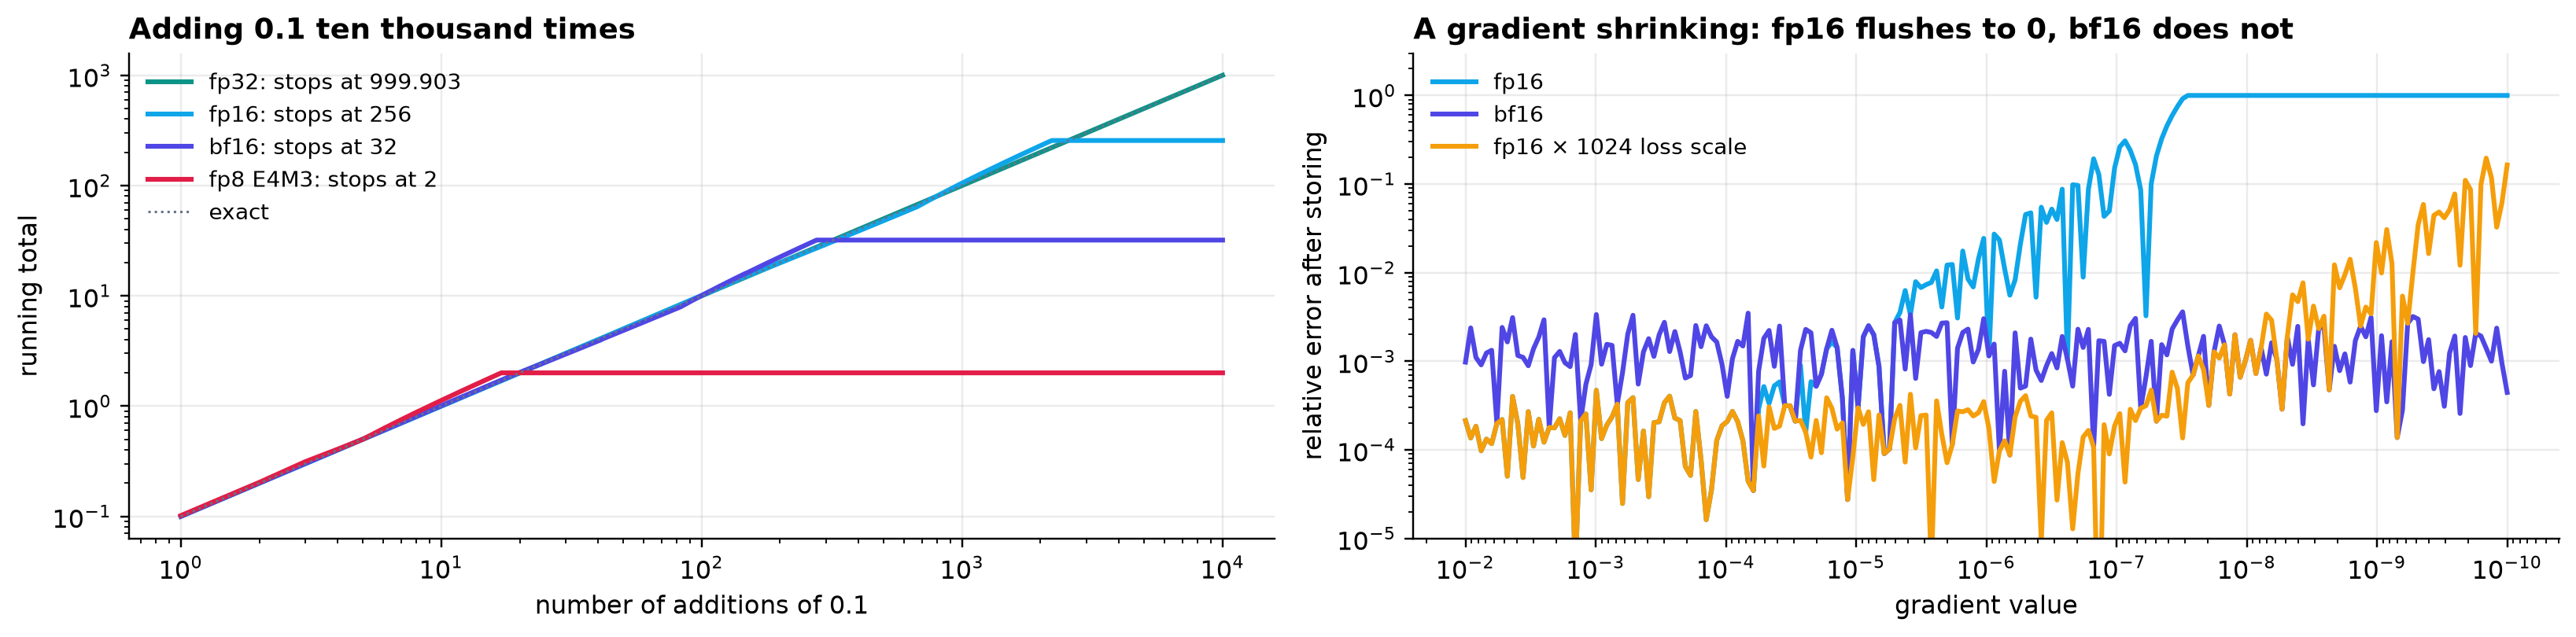

In [ ]:
running_totals = {}
for _name, _dtype in (('fp32', torch.float32), ('fp16', torch.float16), ('bf16', torch.bfloat16), ('fp8 E4M3', torch.float8_e4m3fn)):
    _total = torch.zeros((), dtype=torch.float32)
    _step = torch.tensor(0.1).to(_dtype).float()
    _trace = []
    for _ in range(10_000):
        _total = (_total + _step).to(_dtype).float()          # store the running total in the format every time
        _trace.append(_total.item())
    running_totals[_name] = np.array(_trace)


def _fp8_vs_bf16(n=8192):
    a = torch.randn(n, n, device=dev)
    b = torch.randn(n, n, device=dev)
    ref = a @ b

    def rel(x):
        return ((x.float() - ref).norm() / ref.norm()).item()

    def rate(fn, iters=50):
        for _ in range(5):
            fn()
        sync()
        t0 = time.perf_counter()
        for _ in range(iters):
            fn()
        sync()
        return 2 * n ** 3 * iters / (time.perf_counter() - t0)

    ab, bb = a.bfloat16(), b.bfloat16()
    scale_a, scale_b = a.abs().max() / 448, b.abs().max() / 448          # per-tensor scale into E4M3's ±448 range
    a8 = (a / scale_a).to(torch.float8_e4m3fn)
    b8 = (b / scale_b).to(torch.float8_e4m3fn).t().contiguous().t()      # _scaled_mm wants column-major B
    fp8 = lambda: torch._scaled_mm(a8, b8, scale_a=scale_a.float(), scale_b=scale_b.float(), out_dtype=torch.bfloat16)
    return {'bf16': (rate(lambda: ab @ bb), rel(ab @ bb)), 'fp8 E4M3 (per-tensor scale)': (rate(fp8), rel(fp8()))}


FP8 = cached('fp8_matmul', _fp8_vs_bf16)

_fig, _ax = plt.subplots(1, 2, figsize=(15, 3.8))
for (_name, _trace), _c in zip(running_totals.items(), (TEAL, SKY, INK, ROSE)):
    _ax[0].plot(np.arange(1, 10_001), _trace, color=_c, lw=2, label=f'{_name}: stops at {_trace[-1]:g}')
_ax[0].plot([1, 10_000], [0.1, 1000], color=SLATE, ls=':', lw=1, label='exact')
_ax[0].set(xscale='log', yscale='log', xlabel='number of additions of 0.1', ylabel='running total',
           title='Adding 0.1 ten thousand times')
_ax[0].legend(fontsize=9)

_grads = np.logspace(-2, -10, 200)
for _name, _dtype, _scale, _c in (('fp16', torch.float16, 1.0, SKY), ('bf16', torch.bfloat16, 1.0, INK),
                                  ('fp16 × 1024 loss scale', torch.float16, 1024.0, AMBER)):
    _stored = (torch.tensor(_grads * _scale).to(_dtype).double() / _scale).numpy()
    _ax[1].loglog(_grads, np.abs(_stored - _grads) / _grads + 1e-12, color=_c, lw=2, label=_name)
_ax[1].set(xlabel='gradient value', ylabel='relative error after storing', ylim=(1e-5, 3),
           title='A gradient shrinking: fp16 flushes to 0, bf16 does not')
_ax[1].invert_xaxis()
_ax[1].legend(fontsize=9)
plt.tight_layout()
save(_fig, 'r6-precision.png')

In [ ]:
mo.hstack([
    pd.DataFrame([(g, torch.tensor(g).half().item(), torch.tensor(g).bfloat16().item()) for g in (1e-4, 1e-6, 1e-8)],
                 columns=['gradient', 'fp16 stores', 'bf16 stores']).style.format('{:.3e}'),
    mo.plain(pd.DataFrame([(k, r / 1e12, 100 * e) for k, (r, e) in FP8.items()],
                          columns=['8,192³ matmul', 'TFLOP/s', 'relative error vs fp32 %']).set_index('8,192³ matmul').round(3)),
], justify='start', gap=2)

gradient 
 fp16 stores 
 bf16 stores 
 
 
 
 
 0 
 1.000e-04 
 1.000e-04 
 1.001e-04 
 
 
 1 
 1.000e-06 
 1.013e-06 
 9.984e-07 
 
 
 2 
 1.000e-08 
 0.000e+00 
 1.001e-08 
 
 
 
 TFLOP/s relative error vs fp32 % 8,192³ matmul bf16 410.789 0.287 fp8 E4M3 (per-tensor scale) 803.771 3.756

In [ ]:
_bf, _f8 = FP8['bf16'], FP8['fp8 E4M3 (per-tensor scale)']
mo.md(
    f"""
    **I'd train in bf16 mixed precision.** That means bf16 for matmul inputs and activations, and fp32 for master weights,
    AdamW state and the loss. It is what every run in this notebook used.

    * **Range beats digits.** bf16 keeps fp32's 8 exponent bits, so its smallest normal value is about 1.2 × 10⁻³⁸, while
      fp16's is about 6 × 10⁻⁵ (6 × 10⁻⁸ with subnormals). The measured case above: a 10⁻⁸ gradient is stored as
      **{torch.tensor(1e-8).half().item():g}** in fp16 and as {torch.tensor(1e-8).bfloat16().item():.4g} in bf16. fp16 needs a
      loss scaler to survive, and bf16 does not, so none of the runs here needed `GradScaler`. That is one fewer moving
      part to tune and eventually get wrong.
    * **bf16's rounding error (up to 0.4% per value; 0.1% for 0.1 itself) is fine for *computing* a step, and fatal for *storing* the weights.** Adding 0.1 ten
      thousand times stalls at **{running_totals['bf16'][-1]:g} in bf16**: above 32, neighbouring bf16 values are 0.25 apart, so
      +0.1 rounds away. fp16 stalls at {running_totals['fp16'][-1]:g}. A weight update `w − lr·g` is exactly that kind of tiny
      addition, which is why the master copy stays in fp32 (which reaches {running_totals['fp32'][-1]:.1f}) and why the bill is
      16 bytes per weight.
    * **fp8 E4M3 is fast, and it is not a storage format.** On this Blackwell card it really does deliver: **{_f8[0] / 1e12:.0f} vs
      {_bf[0] / 1e12:.0f} TFLOP/s** ({_f8[0] / _bf[0]:.1f}×) on an 8,192³ matmul. But the relative error is {100 * _f8[1]:.1f}%
      against bf16's {100 * _bf[1]:.2f}%, and 0.1 itself lands on 0.1015625 (1.6% off). With only 8 values between 0.0625 and
      0.125 and a maximum of 448, it needs a scale per tensor (or per block) and only works for matmul inputs, with wide
      accumulators and master weights behind it. Adding 0.1 in E4M3 stalls at {running_totals['fp8 E4M3'][-1]:g}.

    **So bf16 is my default.** I'd put fp8 on the forward and backward matmuls only after a side-by-side run against bf16
    shows the loss curves overlap, which is the open question the lecture leaves for V5. The 2× is real; the risk is a slow
    divergence that only shows up weeks in.
    """
)

**I'd train in bf16 mixed precision.** That means bf16 for matmul inputs and activations, and fp32 for master weights,
AdamW state and the loss. It is what every run in this notebook used.

* **Range beats digits.** bf16 keeps fp32's 8 exponent bits, so its smallest normal value is about 1.2 × 10⁻³⁸, while
  fp16's is about 6 × 10⁻⁵ (6 × 10⁻⁸ with subnormals). The measured case above: a 10⁻⁸ gradient is stored as
  **0** in fp16 and as 1.001e-08 in bf16. fp16 needs a
  loss scaler to survive, and bf16 does not, so none of the runs here needed `GradScaler`. That is one fewer moving
  part to tune and eventually get wrong.
* **bf16's rounding error (up to 0.4% per value; 0.1% for 0.1 itself) is fine for *computing* a step, and fatal for *storing* the weights.** Adding 0.1 ten
  thousand times stalls at **32 in bf16**: above 32, neighbouring bf16 values are 0.25 apart, so
  +0.1 rounds away. fp16 stalls at 256. A weight update `w − lr·g` is exactly that kind of tiny
  addition, which is why the master copy stays in fp32 (which reaches 999.9) and why the bill is
  16 bytes per weight.
* **fp8 E4M3 is fast, and it is not a storage format.** On this Blackwell card it really does deliver: **804 vs
  411 TFLOP/s** (2.0×) on an 8,192³ matmul. But the relative error is 3.8%
  against bf16's 0.29%, and 0.1 itself lands on 0.1015625 (1.6% off). With only 8 values between 0.0625 and
  0.125 and a maximum of 448, it needs a scale per tensor (or per block) and only works for matmul inputs, with wide
  accumulators and master weights behind it. Adding 0.1 in E4M3 stalls at 2.

**So bf16 is my default.** I'd put fp8 on the forward and backward matmuls only after a side-by-side run against bf16
shows the loss curves overlap, which is the open question the lecture leaves for V5. The 2× is real; the risk is a slow
divergence that only shows up weeks in.

## Summary

In [ ]:
_g, _b = grad_check
summary = [
    ('§1 shapes', 'tensors in the bf16 step, all grads = param shape', f'{len(shape_rows)} rows; logits {MAIN_B} × {MAIN_T} × {V:,}'),
    ('§2 gradient by hand', 'float64 relative error',
     f'{min(r[-1] for r in nudge_rows):.0e} – {max(r[-1] for r in nudge_rows):.0e}'),
    ('§3 accumulation', 'gradient error vs one big batch: correct / broken', f'{_g[1]:.1e} / {_b[1]:.2f}'),
    ('§3 accumulation', 'avg-of-averages vs true loss (last 100 steps)', f"{acc_stats['gap_last100']:+.1f}%"),
    ('§3 accumulation', 'held-out loss pos ≥ 16: correct / broken', f"{good['val_long'][-1]:.3f} / {bad['val_long'][-1]:.3f}"),
    ('§4 grad norm', 'step where the norm moved first',
     f"step {spike}: {spike_stats['ratio']:.1f}× median, batch loss z {spike_stats['z']:+.2f}, "
     f"probe +{spike_stats['probe_after'][:3].max() - spike_stats['probe_before']:.3f}"),
    ('§4 grad norm', 'detector onset: norm / probe / batch loss',
     ' / '.join(str(onsets[k]) for k in ('grad norm (log)', 'probe loss', 'batch loss')) + f' (blow-up at {blowup})'),
    ('§5 MFU', f'measured, vs {PEAK / 1e12:.0f} TFLOP/s peak at {GPU["max_sm_mhz"]:.0f} MHz',
     f'{100 * mfu:.1f}% ({flops_tok * tok_per_s / 1e12:.0f} TFLOP/s, {tok_per_s:,.0f} tok/s); best lever {best_lever_mfu:.1f}%'),
    ('§6 0.1', 'fp32 / bf16 / E4M3', ' / '.join(r[2] for r in format_rows)),
    ('§6 0.1', 'fp8 vs bf16 matmul, 8,192³', f"{FP8['fp8 E4M3 (per-tensor scale)'][0] / 1e12:.0f} vs {FP8['bf16'][0] / 1e12:.0f} TFLOP/s"),
]
mo.plain(pd.DataFrame(summary, columns=['section', 'measurement', 'result']).set_index(['section', 'measurement']))

result section measurement §1 shapes tensors in the bf16 step, all grads = param shape 31 rows; logits 16 × 1024 × 50,304 §2 gradient by hand float64 relative error 5e-10 – 5e-09 §3 accumulation gradient error vs one big batch: correct / broken 5.8e-07 / 0.46 avg-of-averages vs true loss (last 100 steps) -14.6% held-out loss pos ≥ 16: correct / broken 2.293 / 2.566 §4 grad norm step where the norm moved first step 238: 2.8× median, batch loss z +0.73, probe +0.583 detector onset: norm / probe / batch loss 469 / 345 / 525 (blow-up at 541) §5 MFU measured, vs 468 TFLOP/s peak at 2430 MHz 33.3% (156 TFLOP/s, 182,343 tok/s); best lever 36.4% §6 0.1 fp32 / bf16 / E4M3 0x3dcccccd / 0x3dcd / 0x1d fp8 vs bf16 matmul, 8,192³ 804 vs 411 TFLOP/s